In [1]:
import sys
from pathlib import Path

print("Python version:", sys.version.split()[0])
DATA_DIR = Path("../data")

print((DATA_DIR / "build_history.csv").exists())
print((DATA_DIR / "homes_to_predict.csv").exists())


Python version: 3.13.2
True
True


# Construction Cycle Time Prediction
## Quantitative Research Analysis

### Research objective

Operations requires a forecast of construction cycle time on the day construction begins.

The primary objective is therefore to estimate expected construction duration using only information available at the construction start date.

The incumbent business benchmark is a per-floor-plan average.

This analysis has three goals:

1. **Forecasting:** determine whether construction-start information can improve out-of-time cycle-time prediction relative to the incumbent floor-plan baseline.

2. **Inference:** identify which observable project and operational characteristics are associated with differences in cycle time, while distinguishing predictive relationships from causal effects.

3. **Decision support:** determine whether the evidence suggests operational actions that could improve scheduling, capacity allocation, or forecast reliability.

## Research design principles

Before inspecting empirical relationships, the analysis will follow five principles:

1. **Prediction-time integrity**  
   Only information genuinely available at construction start may enter the primary forecasting model.

2. **Deployment-realistic validation**  
   Historical observations should predict future observations. Validation will therefore respect time rather than rely primarily on random train/test splitting.

3. **Benchmark before complexity**  
   Any proposed model must be compared against the incumbent per-floor-plan forecasting approach.

4. **Prediction is not inference**  
   A variable that improves prediction does not necessarily cause cycle time to change. Operational conclusions will distinguish predictive value, conditional association, and causal interpretation.

5. **Uncertainty matters**  
   Point forecasts, manager-performance estimates, and operational findings will be interpreted together with their stability, sample size, and uncertainty.

## Pre-analysis questions

Before modeling, the notebook answers the questions that determine whether the analysis is valid:

- What is the target, and which homes have an observed value?
- Which homes are still in progress and therefore censored?
- Which fields were actually available at construction start?
- Which fields contain future information or otherwise fail the information boundary?
- Can the incumbent floor-plan average be reproduced cleanly?
- What time structure exists in the historical sample?
- Which questions are predictive, which are inferential, and which cannot be identified causally?
- What evidence would count against the main operational hypotheses?

## Pre-specified hypotheses

The analysis will focus on three testable hypotheses rather than broad post-hoc feature searching:

1. **Project and context information:** project specification, geography, seasonality, and legitimate construction-start information provide predictive value beyond the incumbent floor-plan average.

2. **Operational congestion:** operational workload at construction start may contain additional information about future cycle time beyond static project characteristics.

3. **Site-manager comparisons:** raw differences in site-manager cycle times may partly reflect differences in the types of projects assigned to each manager rather than manager performance alone.

Evidence that these relationships disappear under out-of-time validation, reasonable adjustment, or relevant subgroup checks will be treated as evidence against the corresponding hypothesis.


## 1. Data audit and target integrity

### Question

Do the two raw exports match the assignment description, and what has to be cleaned or excluded before a target or model can be trusted?

In [2]:
import pandas as pd

# Preserve literal "None"; only empty CSV fields count as missing.
build_history = pd.read_csv(DATA_DIR / "build_history.csv")
homes_to_predict = pd.read_csv(DATA_DIR / "homes_to_predict.csv")

In [3]:
# Verify dataset dimensions against the assignment specification
print(build_history.shape)
print(homes_to_predict.shape)

(4684, 30)
(578, 30)


In [4]:
# Verify that historical and prediction datasets share the same schema
history_columns = build_history.columns.tolist()
prediction_columns = homes_to_predict.columns.tolist()

history_columns == prediction_columns

True

In [5]:
# Inspect the shared raw schema
history_columns

['home_id',
 'community',
 'metro',
 'permit_authority',
 'lot_number',
 'plan_name',
 'plan_code',
 'product_line',
 'beds',
 'baths',
 'half_baths',
 'sqft',
 'stories',
 'garage_size',
 'basement_type',
 'lot_type',
 'lot_size_sqft',
 'is_spec_home',
 'selected_options_value',
 'site_manager',
 'sale_date',
 'permit_application_date',
 'permit_issue_date',
 'construction_start_date',
 'construction_end_date',
 'final_inspection_date',
 'change_order_count',
 'trade_invoice_total',
 'data_source',
 'construction_status']

In [6]:
# Inspect historical construction status and target-date availability

status_counts = build_history["construction_status"].value_counts(dropna=False)

missing_target_dates = (
    build_history[
        ["construction_start_date", "construction_end_date"]
    ]
    .isna()
    .sum()
)

has_observed_target = (
    build_history["construction_start_date"].notna()
    & build_history["construction_end_date"].notna()
)

status_vs_target = pd.crosstab(
    build_history["construction_status"],
    has_observed_target
).rename(
    columns={
        False: "target_unobserved",
        True: "target_observed"
    }
)

print("Construction status counts:")
display(status_counts)

print("\nMissing target-date values:")
display(missing_target_dates)

print("\nConstruction status vs. observed target:")
display(status_vs_target)


Construction status counts:


construction_status
Complete       4105
In Progress     579
Name: count, dtype: int64


Missing target-date values:


construction_start_date      0
construction_end_date      579
dtype: int64


Construction status vs. observed target:


col_0,target_unobserved,target_observed
construction_status,,
Complete,0,4105
In Progress,579,0


### Evidence and interpretation

The historical file contains 4,105 completed builds and 579 in-progress builds. Every home has a construction start date.

The status field and target availability agree exactly: completed homes have an end date, while in-progress homes do not. That leaves 4,105 directly observed durations and 579 unfinished homes whose final durations are still unknown. The unfinished rows are kept in the event history rather than treated as ordinary missing targets.

In [7]:
# Parse target dates and validate observed cycle times
start_dates = pd.to_datetime(
    build_history["construction_start_date"],
    errors="coerce"
)

end_dates = pd.to_datetime(
    build_history["construction_end_date"],
    errors="coerce"
)

cycle_time_days = (end_dates - start_dates).dt.days

observed_cycle_times = cycle_time_days[has_observed_target]

print("Observed cycle-time summary:")
display(observed_cycle_times.describe())

print("\nNon-positive cycle times:")
print((observed_cycle_times <= 0).sum())

invalid_start_dates = (
    build_history["construction_start_date"].notna()
    & start_dates.isna()
).sum()

invalid_end_dates = (
    build_history["construction_end_date"].notna()
    & end_dates.isna()
).sum()

print("\nInvalid non-missing date strings:")
print("construction_start_date:", invalid_start_dates)
print("construction_end_date:", invalid_end_dates)

Observed cycle-time summary:


count    4105.000000
mean      187.132521
std        63.050047
min        -8.000000
25%       140.000000
50%       178.000000
75%       224.000000
max       622.000000
dtype: float64


Non-positive cycle times:
7

Invalid non-missing date strings:
construction_start_date: 0
construction_end_date: 0


In [8]:
# Inspect completed builds with non-positive cycle times
invalid_cycle_mask = (
    has_observed_target
    & (cycle_time_days <= 0)
)

invalid_cycle_rows = build_history.loc[
    invalid_cycle_mask,
    [
        "home_id",
        "construction_status",
        "construction_start_date",
        "construction_end_date",
        "final_inspection_date",
        "community",
        "plan_name",
        "site_manager"
    ]
].copy()

invalid_cycle_rows["cycle_time_days"] = cycle_time_days[invalid_cycle_mask]

display(invalid_cycle_rows)

,home_id,construction_status,construction_start_date,construction_end_date,final_inspection_date,community,plan_name,site_manager,cycle_time_days
624,H100392,Complete,2021-07-02,2021-06-25,2022-03-05,Windermere,Larch,G. Ramirez,-7.0
1117,H103515,Complete,2024-08-10,2024-08-08,2024-12-16,Riverbend,Dogwood,V. Okonkwo,-2.0
2955,H103849,Complete,2024-11-26,2024-11-21,2025-04-21,Riverbend,Hawthorn,L. Mwangi,-5.0
3726,H103689,Complete,2024-10-01,2024-09-27,2025-01-17,Windermere,Dogwood,H. Lindqvist,-4.0
3962,H101045,Complete,2022-04-10,2022-04-02,2022-12-01,Mahogany Point,Katsura,L. Mwangi,-8.0
4216,H101204,Complete,2022-06-03,2022-06-01,2023-04-12,Wildgrass,Nyssa,P. Sandoval,-2.0
4632,H101439,Complete,2022-08-28,2022-08-25,2023-03-12,Windermere,Larch,P. Sandoval,-3.0


### Evidence and treatment

Seven completed rows have non-positive cycle times because the recorded end date is on or before the start date. Those targets are invalid and are excluded from supervised target analysis.

The source rows are kept for auditability. Positive long-duration builds are not removed just because they are extreme.

In [9]:
# Define the valid observed-target sample for supervised analysis

valid_target_mask = (
    has_observed_target
    & (cycle_time_days > 0)
)

valid_cycle_times = cycle_time_days[valid_target_mask]

print("Valid observed targets:", valid_target_mask.sum())
print("Excluded non-positive targets:", invalid_cycle_mask.sum())

display(valid_cycle_times.describe())

Valid observed targets: 4098
Excluded non-positive targets: 7


count    4098.000000
mean      187.459736
std        62.604219
min        65.000000
25%       140.000000
50%       178.000000
75%       224.000000
max       622.000000
dtype: float64

In [10]:
# Check home-level uniqueness and overlap across historical and prediction datasets

history_duplicate_ids = build_history["home_id"].duplicated(keep=False)
prediction_duplicate_ids = homes_to_predict["home_id"].duplicated(keep=False)

history_exact_duplicates = build_history.duplicated().sum()
prediction_exact_duplicates = homes_to_predict.duplicated().sum()

overlapping_home_ids = set(build_history["home_id"]).intersection(
    set(homes_to_predict["home_id"])
)

print("Historical duplicate home_id rows:", history_duplicate_ids.sum())
print("Prediction duplicate home_id rows:", prediction_duplicate_ids.sum())

print("\nExact duplicate historical rows:", history_exact_duplicates)
print("Exact duplicate prediction rows:", prediction_exact_duplicates)

print("\nHome IDs appearing in both files:", len(overlapping_home_ids))

Historical duplicate home_id rows: 50
Prediction duplicate home_id rows: 0

Exact duplicate historical rows: 25
Exact duplicate prediction rows: 0

Home IDs appearing in both files: 0


In [11]:
if history_duplicate_ids.any():
    display(
        build_history.loc[history_duplicate_ids]
        .sort_values("home_id")
    )

if prediction_duplicate_ids.any():
    display(
        homes_to_predict.loc[prediction_duplicate_ids]
        .sort_values("home_id")
    )

,home_id,community,metro,permit_authority,lot_number,plan_name,plan_code,product_line,beds,baths,...,sale_date,permit_application_date,permit_issue_date,construction_start_date,construction_end_date,final_inspection_date,change_order_count,trade_invoice_total,data_source,construction_status
3000,H100128,Windermere,Edmonton,City of Edmonton,296,Ironwood,SF-303,Single Family,4.0,3,...,NaN,2021-01-22,2021-02-12,2021-03-11,2021-08-20,2021-08-18,0,496300.0,BUILDPRO_EXPORT,Complete
844,H100128,Windermere,Edmonton,City of Edmonton,296,Ironwood,SF-303,Single Family,4.0,3,...,NaN,2021-01-22,2021-02-12,2021-03-11,2021-08-20,2021-08-18,0,496300.0,BUILDPRO_EXPORT,Complete
1134,H100347,Sterling Ranch,Denver,Douglas County,219,Maple,SF-308,Single Family,5.0,4,...,2021-01-16,2021-04-20,2021-05-10,2021-06-16,2021-12-14,2021-12-11,2,562800.0,BUILDPRO_EXPORT,Complete
2938,H100347,Sterling Ranch,Denver,Douglas County,219,Maple,SF-308,Single Family,5.0,4,...,2021-01-16,2021-04-20,2021-05-10,2021-06-16,2021-12-14,2021-12-11,2,562800.0,BUILDPRO_EXPORT,Complete
428,H100437,Green Valley,Denver,City of Denver,398,Larch,SF-307,Single Family,5.0,4,...,2021-04-30,2021-05-23,2021-06-03,2021-07-22,2022-04-20,2022-04-17,2,722900.0,BUILDPRO_EXPORT,Complete
4206,H100437,Green Valley,Denver,City of Denver,398,Larch,SF-307,Single Family,5.0,4,...,2021-04-30,2021-05-23,2021-06-03,2021-07-22,2022-04-20,2022-04-17,2,722900.0,BUILDPRO_EXPORT,Complete
2435,H100563,Riverbend,Calgary,City of Calgary,265,Oakmont,SF-302,Single Family,3.0,3,...,2021-04-15,2021-04-21,2021-07-28,2021-09-08,2022-02-01,2022-01-28,1,498600.0,BUILDPRO_EXPORT,Complete
3408,H100563,Riverbend,Calgary,City of Calgary,265,Oakmont,SF-302,Single Family,3.0,3,...,2021-04-15,2021-04-21,2021-07-28,2021-09-08,2022-02-01,2022-01-28,1,498600.0,BUILDPRO_EXPORT,Complete
3468,H100692,Laurel Green,Edmonton,City of Edmonton,310,Nyssa,SF-309,Single Family,5.0,5,...,2021-06-09,2021-09-15,2021-09-26,2021-10-29,2022-08-02,2022-07-29,3,882600.0,BUILDPRO_EXPORT,Complete
1103,H100692,Laurel Green,Edmonton,City of Edmonton,310,Nyssa,SF-309,Single Family,5.0,5,...,2021-06-09,2021-09-15,2021-09-26,2021-10-29,2022-08-02,2022-07-29,3,882600.0,BUILDPRO_EXPORT,Complete


In [12]:
# Verify that duplicated home IDs are fully explained by exact repeated records

history_without_exact_duplicates = build_history.drop_duplicates()

remaining_duplicate_ids = (
    history_without_exact_duplicates["home_id"]
    .duplicated(keep=False)
)

print(
    "Unique duplicated home IDs:",
    build_history.loc[history_duplicate_ids, "home_id"].nunique()
)

print(
    "Historical rows before exact deduplication:",
    len(build_history)
)

print(
    "Historical rows after exact deduplication:",
    len(history_without_exact_duplicates)
)

print(
    "Duplicate home_id rows remaining after exact deduplication:",
    remaining_duplicate_ids.sum()
)

Unique duplicated home IDs: 25
Historical rows before exact deduplication: 4684
Historical rows after exact deduplication: 4659
Duplicate home_id rows remaining after exact deduplication: 0


### Duplicate-record treatment

Twenty-five homes appear twice as exact row duplicates. Removing one copy of each pair reduces the historical file from 4,684 to 4,659 rows, and no duplicate `home_id` remains.

Only exact repeated exports are removed. No conflicting home record is resolved by assumption.

In [13]:
# Create the deduplicated working historical dataset

history_clean = build_history.drop_duplicates().copy()

print("Working historical rows:", len(history_clean))
print(
    "Remaining duplicate home IDs:",
    history_clean["home_id"].duplicated().sum()
)

Working historical rows: 4659
Remaining duplicate home IDs: 0


In [14]:
# Reconstruct target information on the deduplicated historical dataset

history_clean["construction_start_date"] = pd.to_datetime(
    history_clean["construction_start_date"],
    errors="coerce"
)

history_clean["construction_end_date"] = pd.to_datetime(
    history_clean["construction_end_date"],
    errors="coerce"
)

history_clean["cycle_time_days"] = (
    history_clean["construction_end_date"]
    - history_clean["construction_start_date"]
).dt.days

history_clean["has_observed_target"] = (
    history_clean["construction_start_date"].notna()
    & history_clean["construction_end_date"].notna()
)

history_clean["valid_target"] = (
    history_clean["has_observed_target"]
    & (history_clean["cycle_time_days"] > 0)
)

print("Working historical rows:", len(history_clean))
print("Observed targets:", history_clean["has_observed_target"].sum())
print("Valid positive targets:", history_clean["valid_target"].sum())
print(
    "Invalid non-positive targets:",
    (
        history_clean["has_observed_target"]
        & ~history_clean["valid_target"]
    ).sum()
)

Working historical rows: 4659
Observed targets: 4084
Valid positive targets: 4077
Invalid non-positive targets: 7


In [15]:
# Compare raw-feature missingness between historical and prediction datasets

raw_columns = history_columns

history_missingness = pd.DataFrame({
    "history_missing_count": history_clean[raw_columns].isna().sum(),
    "history_missing_pct": history_clean[raw_columns].isna().mean() * 100,
    "prediction_missing_count": homes_to_predict[raw_columns].isna().sum(),
    "prediction_missing_pct": homes_to_predict[raw_columns].isna().mean() * 100,
})

history_missingness = history_missingness[
    (history_missingness["history_missing_count"] > 0)
    | (history_missingness["prediction_missing_count"] > 0)
].sort_values(
    "history_missing_pct",
    ascending=False
)

display(
    history_missingness.round(1)
)

,history_missing_count,history_missing_pct,prediction_missing_count,prediction_missing_pct
basement_type,1644,35.3,260,45.0
sale_date,1577,33.8,196,33.9
construction_end_date,575,12.3,578,100.0
final_inspection_date,575,12.3,578,100.0
beds,139,3.0,17,2.9
lot_size_sqft,97,2.1,12,2.1
change_order_count,0,0.0,578,100.0
trade_invoice_total,0,0.0,578,100.0


### Missingness and prediction-time availability

`sale_date` is missing for about one-third of both files. `beds` and `lot_size_sqft` have small amounts of missingness. Numeric imputation, when needed by a model, is fitted on training data only.

One parser detail matters: `None` is a valid `basement_type` category in the data dictionary. The loader preserves that literal value and treats only actual blank fields as missing. A genuinely missing basement value is labeled `Unknown`; it is not silently converted to `None`.

`construction_end_date`, `final_inspection_date`, `change_order_count`, and `trade_invoice_total` are unavailable for every prediction row. Their timing and meaning also place them outside the construction-start information set.

In [16]:
# Audit sale-date availability relative to the construction-start prediction timestamp

history_clean["sale_date"] = pd.to_datetime(
    history_clean["sale_date"],
    errors="coerce"
)

prediction_start_dates = pd.to_datetime(
    homes_to_predict["construction_start_date"],
    errors="coerce"
)

prediction_sale_dates = pd.to_datetime(
    homes_to_predict["sale_date"],
    errors="coerce"
)

history_sale_timing = pd.Series({
    "missing_sale_date": history_clean["sale_date"].isna().sum(),
    "sale_on_or_before_start": (
        history_clean["sale_date"].notna()
        & (
            history_clean["sale_date"]
            <= history_clean["construction_start_date"]
        )
    ).sum(),
    "sale_after_start": (
        history_clean["sale_date"].notna()
        & (
            history_clean["sale_date"]
            > history_clean["construction_start_date"]
        )
    ).sum(),
})

prediction_sale_timing = pd.Series({
    "missing_sale_date": prediction_sale_dates.isna().sum(),
    "sale_on_or_before_start": (
        prediction_sale_dates.notna()
        & (prediction_sale_dates <= prediction_start_dates)
    ).sum(),
    "sale_after_start": (
        prediction_sale_dates.notna()
        & (prediction_sale_dates > prediction_start_dates)
    ).sum(),
})

print("Historical sale timing:")
display(history_sale_timing)

print("\nPrediction-set sale timing:")
display(prediction_sale_timing)

Historical sale timing:


missing_sale_date          1577
sale_on_or_before_start    3082
sale_after_start              0
dtype: int64


Prediction-set sale timing:


missing_sale_date          196
sale_on_or_before_start    382
sale_after_start             0
dtype: int64

### Sale-date availability

Every observed `sale_date` falls on or before `construction_start_date` in both files. On recorded timing, it does not contain direct future-date leakage.

The field is still missing for many homes, so the model must preserve the distinction between a recorded pre-start sale and no recorded sale.

In [17]:
# Audit permit-date timing relative to construction start

history_clean["permit_application_date"] = pd.to_datetime(
    history_clean["permit_application_date"],
    errors="coerce"
)

history_clean["permit_issue_date"] = pd.to_datetime(
    history_clean["permit_issue_date"],
    errors="coerce"
)

prediction_permit_application = pd.to_datetime(
    homes_to_predict["permit_application_date"],
    errors="coerce"
)

prediction_permit_issue = pd.to_datetime(
    homes_to_predict["permit_issue_date"],
    errors="coerce"
)

permit_timing = pd.DataFrame({
    "history_after_start": [
        (
            history_clean["permit_application_date"].notna()
            & (
                history_clean["permit_application_date"]
                > history_clean["construction_start_date"]
            )
        ).sum(),
        (
            history_clean["permit_issue_date"].notna()
            & (
                history_clean["permit_issue_date"]
                > history_clean["construction_start_date"]
            )
        ).sum(),
    ],
    "prediction_after_start": [
        (
            prediction_permit_application.notna()
            & (prediction_permit_application > prediction_start_dates)
        ).sum(),
        (
            prediction_permit_issue.notna()
            & (prediction_permit_issue > prediction_start_dates)
        ).sum(),
    ],
}, index=[
    "permit_application_date",
    "permit_issue_date"
])

display(permit_timing)

,history_after_start,prediction_after_start
permit_application_date,0,0
permit_issue_date,0,0


### Permit-date availability

All observed permit application and issue dates occur on or before construction start. On timing grounds, both fields are eligible start-day inputs.

In [18]:
# Inspect categorical fields for inconsistent capitalization and spelling

categorical_columns = [
    "community",
    "metro",
    "permit_authority",
    "plan_name",
    "plan_code",
    "product_line",
    "garage_size",
    "basement_type",
    "lot_type",
    "is_spec_home",
    "site_manager",
    "data_source",
    "construction_status",
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print("Unique values:", history_clean[column].nunique(dropna=False))
    display(
        history_clean[column]
        .value_counts(dropna=False)
        .sort_index()
    )


--- community ---
Unique values: 70


community
 Auburn Meadows       6
 Aurora Highlands     7
 Barefoot Lakes       6
 Cranston Ridge       3
 Glenridding          8
                     ..
mahogany point        6
riverbend             4
sterling ranch        9
wildgrass             7
windermere           12
Name: count, Length: 70, dtype: int64


--- metro ---
Unique values: 3


metro
Calgary     1643
Denver      1627
Edmonton    1389
Name: count, dtype: int64


--- permit_authority ---
Unique values: 7


permit_authority
Adams County          667
City of Calgary       969
City of Denver        317
City of Edmonton     1054
Douglas County        643
Leduc County          335
Rocky View County     674
Name: count, dtype: int64

... (16 outputs left out)


--- data_source ---
Unique values: 1


data_source
BUILDPRO_EXPORT    4659
Name: count, dtype: int64


--- construction_status ---
Unique values: 2


construction_status
Complete       4084
In Progress     575
Name: count, dtype: int64

In [19]:
# Quantify categorical normalization issues in history and prediction datasets

def normalized_unique_count(series):
    return (
        series
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .nunique()
    )

category_normalization_check = pd.DataFrame({
    "history_raw_unique": [
        history_clean["community"].nunique(dropna=True),
        history_clean["garage_size"].nunique(dropna=True),
    ],
    "history_normalized_unique": [
        normalized_unique_count(history_clean["community"]),
        normalized_unique_count(history_clean["garage_size"]),
    ],
    "prediction_raw_unique": [
        homes_to_predict["community"].nunique(dropna=True),
        homes_to_predict["garage_size"].nunique(dropna=True),
    ],
    "prediction_normalized_unique": [
        normalized_unique_count(homes_to_predict["community"]),
        normalized_unique_count(homes_to_predict["garage_size"]),
    ],
}, index=[
    "community",
    "garage_size",
])

display(category_normalization_check)

print("\nHistorical garage-size values:")
display(history_clean["garage_size"].value_counts(dropna=False))

print("\nPrediction garage-size values:")
display(homes_to_predict["garage_size"].value_counts(dropna=False))

,history_raw_unique,history_normalized_unique,prediction_raw_unique,prediction_normalized_unique
community,70,14,45,14
garage_size,6,6,6,6



Historical garage-size values:


garage_size
2         1762
3         1356
1         1285
Double      99
Triple      83
Single      74
Name: count, dtype: int64


Prediction garage-size values:


garage_size
1         232
2         196
3         119
Triple     11
Single     10
Double     10
Name: count, dtype: int64

In [20]:
# Create normalized categorical fields in the working datasets

prediction_clean = homes_to_predict.copy()

history_clean["community_clean"] = (
    history_clean["community"]
    .str.strip()
    .str.title()
)

prediction_clean["community_clean"] = (
    prediction_clean["community"]
    .str.strip()
    .str.title()
)

garage_size_map = {
    "1": 1,
    "Single": 1,
    "2": 2,
    "Double": 2,
    "3": 3,
    "Triple": 3,
}

history_clean["garage_size_clean"] = (
    history_clean["garage_size"]
    .astype(str)
    .str.strip()
    .map(garage_size_map)
)

prediction_clean["garage_size_clean"] = (
    prediction_clean["garage_size"]
    .astype(str)
    .str.strip()
    .map(garage_size_map)
)

history_clean["basement_type_clean"] = (
    history_clean["basement_type"]
    .fillna("Unknown")
)

prediction_clean["basement_type_clean"] = (
    prediction_clean["basement_type"]
    .fillna("Unknown")
)

print(
    "Historical normalized communities:",
    history_clean["community_clean"].nunique()
)

print(
    "Prediction normalized communities:",
    prediction_clean["community_clean"].nunique()
)

print(
    "Historical normalized garage sizes:",
    sorted(history_clean["garage_size_clean"].dropna().unique())
)

print(
    "Prediction normalized garage sizes:",
    sorted(prediction_clean["garage_size_clean"].dropna().unique())
)

print("\nHistorical basement types:")
display(history_clean["basement_type_clean"].value_counts())

print("\nPrediction basement types:")
display(prediction_clean["basement_type_clean"].value_counts())

print(
    "\nCommunities appearing only in prediction:",
    sorted(
        set(prediction_clean["community_clean"].dropna())
        - set(history_clean["community_clean"].dropna())
    )
)

print(
    "Communities appearing only in history:",
    sorted(
        set(history_clean["community_clean"].dropna())
        - set(prediction_clean["community_clean"].dropna())
    )
)


Historical normalized communities: 14
Prediction normalized communities: 14
Historical normalized garage sizes: [np.int64(1), np.int64(2), np.int64(3)]
Prediction normalized garage sizes: [np.int64(1), np.int64(2), np.int64(3)]

Historical basement types:


basement_type_clean
Unfinished    2043
Unknown       1644
Finished       972
Name: count, dtype: int64


Prediction basement types:


basement_type_clean
Unknown       260
Unfinished    215
Finished      103
Name: count, dtype: int64


Communities appearing only in prediction: []
Communities appearing only in history: []


In [21]:
# Audit floor-plan identity and prediction-set coverage for the incumbent baseline

plans_per_code = (
    history_clean
    .groupby("plan_code")["plan_name"]
    .nunique()
)

codes_per_plan = (
    history_clean
    .groupby("plan_name")["plan_code"]
    .nunique()
)

history_plan_pairs = set(
    map(
        tuple,
        history_clean[
            ["plan_name", "plan_code"]
        ].drop_duplicates().to_numpy()
    )
)

prediction_plan_pairs = set(
    map(
        tuple,
        prediction_clean[
            ["plan_name", "plan_code"]
        ].drop_duplicates().to_numpy()
    )
)

unseen_plan_pairs = sorted(
    prediction_plan_pairs - history_plan_pairs
)

print("Historical plan names:", history_clean["plan_name"].nunique())
print("Historical plan codes:", history_clean["plan_code"].nunique())

print(
    "Maximum plan names associated with one plan code:",
    plans_per_code.max()
)

print(
    "Maximum plan codes associated with one plan name:",
    codes_per_plan.max()
)

print(
    "Floor-plan combinations appearing only in prediction:",
    unseen_plan_pairs
)

Historical plan names: 16
Historical plan codes: 16
Maximum plan names associated with one plan code: 1
Maximum plan codes associated with one plan name: 1
Floor-plan combinations appearing only in prediction: []


### Floor-plan coverage

`plan_name` and `plan_code` form a one-to-one mapping across 16 plans. Every plan combination in the prediction set also appears in history.

The final prediction batch therefore does not require an unseen-plan fallback for the incumbent benchmark, although the model code still defines one.

In [22]:
# Inspect historical and prediction-set construction-start coverage over time

prediction_clean["construction_start_date"] = pd.to_datetime(
    prediction_clean["construction_start_date"],
    errors="coerce"
)

temporal_coverage = pd.DataFrame({
    "history": [
        history_clean["construction_start_date"].min(),
        history_clean["construction_start_date"].max(),
    ],
    "prediction": [
        prediction_clean["construction_start_date"].min(),
        prediction_clean["construction_start_date"].max(),
    ],
}, index=[
    "earliest_start",
    "latest_start",
])

display(temporal_coverage)

history_starts_by_year = (
    history_clean["construction_start_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

prediction_starts_by_year = (
    prediction_clean["construction_start_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nHistorical construction starts by year:")
display(history_starts_by_year)

print("\nPrediction construction starts by year:")
display(prediction_starts_by_year)

,history,prediction
earliest_start,2021-01-04,2025-08-01
latest_start,2025-07-31,2025-12-31



Historical construction starts by year:


construction_start_date
2021     823
2022     981
2023    1039
2024    1117
2025     699
Name: count, dtype: int64


Prediction construction starts by year:


construction_start_date
2025    578
Name: count, dtype: int64

### Temporal coverage

Historical starts run from January 2021 through July 31, 2025. The prediction set begins on August 1, 2025 and runs through December 2025.

The requested predictions are the next chronological block after the historical sample, which makes forward-in-time validation the natural primary design.

In [23]:
# Audit sales-related fields against the construction-start information boundary

history_sales_audit = pd.Series({
    "spec_homes": history_clean["is_spec_home"].sum(),
    "spec_homes_with_sale_date": (
        history_clean["is_spec_home"]
        & history_clean["sale_date"].notna()
    ).sum(),
    "spec_homes_with_nonzero_options": (
        history_clean["is_spec_home"]
        & (history_clean["selected_options_value"].fillna(0) > 0)
    ).sum(),
})

prediction_sales_audit = pd.Series({
    "spec_homes": prediction_clean["is_spec_home"].sum(),
    "spec_homes_with_sale_date": (
        prediction_clean["is_spec_home"]
        & prediction_sale_dates.notna()
    ).sum(),
    "spec_homes_with_nonzero_options": (
        prediction_clean["is_spec_home"]
        & (prediction_clean["selected_options_value"].fillna(0) > 0)
    ).sum(),
})

print("Historical sales-field audit:")
display(history_sales_audit)

print("\nPrediction-set sales-field audit:")
display(prediction_sales_audit)

Historical sales-field audit:


spec_homes                         1076
spec_homes_with_sale_date             0
spec_homes_with_nonzero_options    1076
dtype: int64


Prediction-set sales-field audit:


spec_homes                         134
spec_homes_with_sale_date            0
spec_homes_with_nonzero_options    134
dtype: int64

### Sales-field interpretation

`is_spec_home` is consistent with its definition: spec homes have no recorded `sale_date` at construction start.

`selected_options_value` is harder to interpret. Every spec home still has a positive value even though the field is described as buyer-selected upgrades. The field may include builder-selected packages or another broader concept. Because its timestamp is also unverified, it is kept out of the eligible primary feature set and used only in a diagnostic sensitivity.

In [24]:
# Summarize prediction-time eligibility of raw fields

feature_audit = pd.DataFrame([
    ("home_id", "identifier only", "Unique home identifier"),
    ("data_source", "exclude", "Constant export metadata"),
    ("community", "valid", "Known at construction start; normalized for casing/spacing"),
    ("metro", "valid", "Known at construction start"),
    ("permit_authority", "valid", "Known at construction start"),
    ("lot_number", "conditionally valid", "Known at start but potentially identifier-like"),
    ("plan_name", "valid", "Known project specification"),
    ("plan_code", "valid", "Known project specification; one-to-one with plan_name"),
    ("product_line", "valid", "Known project specification"),
    ("beds", "valid", "Known specification; small amount of missingness"),
    ("baths", "valid", "Known project specification"),
    ("half_baths", "valid", "Known project specification"),
    ("sqft", "valid", "Known project specification; likely scaling errors; model correction fitted on training only"),
    ("stories", "valid", "Known project specification"),
    ("garage_size", "valid", "Known specification; normalized to cars"),
    ("basement_type", "valid", "Literal None preserved by the CSV reader; actual missingness remains Unknown"),
    ("lot_type", "valid", "Known lot characteristic"),
    ("lot_size_sqft", "valid", "Known lot characteristic; small amount of missingness"),
    ("is_spec_home", "valid", "Defined as unsold at construction start"),
    ("sale_date", "valid when present", "All observed sale dates occur on or before construction start"),
    ("selected_options_value", "conditionally valid", "Present in prediction data, but timing and semantics are ambiguous for spec homes"),
    ("site_manager", "valid", "Assume export records the manager assigned at start; reassignment history unavailable"),
    ("permit_application_date", "valid", "Always on or before construction start"),
    ("permit_issue_date", "valid", "Always on or before construction start"),
    ("construction_start_date", "valid", "Prediction timestamp; useful for calendar features"),
    ("construction_end_date", "target / leakage", "Defines the target and occurs after prediction"),
    ("final_inspection_date", "post-start / leakage", "Future construction outcome information"),
    ("change_order_count", "post-start / leakage", "Unavailable for all prediction homes"),
    ("trade_invoice_total", "post-start / leakage", "Unavailable for all prediction homes"),
    ("construction_status", "exclude", "Outcome-process field and non-informative at construction-start prediction"),
], columns=[
    "field",
    "classification",
    "reason"
])

display(feature_audit)


,field,classification,reason
0,home_id,identifier only,Unique home identifier
1,data_source,exclude,Constant export metadata
2,community,valid,Known at construction start; normalized for ca...
3,metro,valid,Known at construction start
4,permit_authority,valid,Known at construction start
5,lot_number,conditionally valid,Known at start but potentially identifier-like
6,plan_name,valid,Known project specification
7,plan_code,valid,Known project specification; one-to-one with p...
8,product_line,valid,Known project specification
9,beds,valid,Known specification; small amount of missingness


### Numeric feature integrity

Numeric project fields are checked for sign errors and obvious scale problems before modeling. Square footage is inspected within floor plan so a large but plausible home is not confused with a data-entry error.

In [25]:
# Inspect square-footage ranges within each floor plan

history_sqft_by_plan = (
    history_clean
    .groupby(["plan_code", "plan_name"])["sqft"]
    .agg(["count", "min", "median", "max"])
)

prediction_sqft_by_plan = (
    prediction_clean
    .groupby(["plan_code", "plan_name"])["sqft"]
    .agg(["count", "min", "median", "max"])
)

print("Historical sqft ranges by floor plan:")
display(history_sqft_by_plan)

print("\nPrediction sqft ranges by floor plan:")
display(prediction_sqft_by_plan)

Historical sqft ranges by floor plan:


,,count,min,median,max
plan_code,plan_name,,,,
DX-201,Elm,215,1410,1560.0,1780
DX-202,Fir,249,1490,1680.0,1900
DX-203,Ginkgo,261,1550,1740.0,16600
SF-301,Hawthorn,264,1610,1840.0,19400
SF-302,Oakmont,288,1920,2200.0,23100
SF-303,Ironwood,283,1820,2100.0,2340
SF-304,Juniper,293,2080,2350.0,2650
SF-305,Katsura,279,2250,2610.0,26200
SF-306,Poplar,296,2450,2760.0,3100



Prediction sqft ranges by floor plan:


,,count,min,median,max
plan_code,plan_name,,,,
DX-201,Elm,27,1420,1530.0,1680
DX-202,Fir,33,1580,1690.0,1780
DX-203,Ginkgo,34,1630,1740.0,1910
SF-301,Hawthorn,28,1680,1845.0,2030
SF-302,Oakmont,30,2000,2200.0,2360
SF-303,Ironwood,36,1950,2110.0,2250
SF-304,Juniper,28,2090,2325.0,23200
SF-305,Katsura,22,2370,2635.0,2770
SF-306,Poplar,20,2530,2785.0,27700


### Square-footage evidence

Several plans contain values roughly an order of magnitude above an otherwise tight plan-specific range. The pattern is consistent with a factor-of-ten entry problem, but the rows are inspected before any correction rule is defined.

In [26]:
# Inspect suspicious square-footage values using historical plan-level references

plan_sqft_medians = (
    history_clean
    .groupby("plan_code")["sqft"]
    .median()
)

history_sqft_median = (
    history_clean["plan_code"]
    .map(plan_sqft_medians)
)

prediction_sqft_median = (
    prediction_clean["plan_code"]
    .map(plan_sqft_medians)
)

history_sqft_suspicious = (
    history_clean["sqft"] > 3 * history_sqft_median
)

prediction_sqft_suspicious = (
    prediction_clean["sqft"] > 3 * prediction_sqft_median
)

print("Suspicious historical sqft rows:")
display(
    history_clean.loc[
        history_sqft_suspicious,
        ["home_id", "plan_code", "plan_name", "sqft"]
    ]
)

print("\nSuspicious prediction sqft rows:")
display(
    prediction_clean.loc[
        prediction_sqft_suspicious,
        ["home_id", "plan_code", "plan_name", "sqft"]
    ]
)


Suspicious historical sqft rows:


,home_id,plan_code,plan_name,sqft
341,H102544,SF-305,Katsura,26200
351,H100569,SF-309,Nyssa,34900
461,H100767,SF-302,Oakmont,23100
800,H102804,SF-307,Larch,30800
959,H101916,SF-302,Oakmont,22000
1009,H100450,SF-308,Maple,30500
1321,H103786,TH-101,Aspen,12200
1464,H104353,TH-101,Aspen,12300
2461,H101327,DX-203,Ginkgo,16600
3257,H100489,SF-307,Larch,30600



Suspicious prediction sqft rows:


,home_id,plan_code,plan_name,sqft
4,H105155,SF-304,Juniper,23200
62,H105124,TH-103,Cedar,13700
131,H105005,SF-306,Poplar,27700


In [27]:
# Verify whether suspicious square-footage values are consistent with factor-of-10 errors

history_sqft_check = history_clean.loc[
    history_sqft_suspicious,
    ["home_id", "plan_code", "plan_name", "sqft"]
].copy()

history_sqft_check["plan_median_sqft"] = (
    history_sqft_median[history_sqft_suspicious]
)

history_sqft_check["sqft_divided_by_10"] = (
    history_sqft_check["sqft"] / 10
)

history_sqft_check["corrected_to_median_ratio"] = (
    history_sqft_check["sqft_divided_by_10"]
    / history_sqft_check["plan_median_sqft"]
)

prediction_sqft_check = prediction_clean.loc[
    prediction_sqft_suspicious,
    ["home_id", "plan_code", "plan_name", "sqft"]
].copy()

prediction_sqft_check["plan_median_sqft"] = (
    prediction_sqft_median[prediction_sqft_suspicious]
)

prediction_sqft_check["sqft_divided_by_10"] = (
    prediction_sqft_check["sqft"] / 10
)

prediction_sqft_check["corrected_to_median_ratio"] = (
    prediction_sqft_check["sqft_divided_by_10"]
    / prediction_sqft_check["plan_median_sqft"]
)

print("Historical factor-of-10 check:")
display(history_sqft_check.round(2))

print("\nPrediction factor-of-10 check:")
display(prediction_sqft_check.round(2))

Historical factor-of-10 check:


,home_id,plan_code,plan_name,sqft,plan_median_sqft,sqft_divided_by_10,corrected_to_median_ratio
341,H102544,SF-305,Katsura,26200,2610.0,2620.0,1.00
351,H100569,SF-309,Nyssa,34900,3410.0,3490.0,1.02
461,H100767,SF-302,Oakmont,23100,2200.0,2310.0,1.05
800,H102804,SF-307,Larch,30800,2860.0,3080.0,1.08
959,H101916,SF-302,Oakmont,22000,2200.0,2200.0,1.00
1009,H100450,SF-308,Maple,30500,3095.0,3050.0,0.99
1321,H103786,TH-101,Aspen,12200,1180.0,1220.0,1.03
1464,H104353,TH-101,Aspen,12300,1180.0,1230.0,1.04
2461,H101327,DX-203,Ginkgo,16600,1740.0,1660.0,0.95
3257,H100489,SF-307,Larch,30600,2860.0,3060.0,1.07



Prediction factor-of-10 check:


,home_id,plan_code,plan_name,sqft,plan_median_sqft,sqft_divided_by_10,corrected_to_median_ratio
4,H105155,SF-304,Juniper,23200,2350.0,2320.0,0.99
62,H105124,TH-103,Cedar,13700,1420.0,1370.0,0.96
131,H105005,SF-306,Poplar,27700,2760.0,2770.0,1.00


In [28]:
# Descriptive repair only; forecasting refits this rule on each training sample

history_clean["sqft_clean"] = history_clean["sqft"].copy()
prediction_clean["sqft_clean"] = prediction_clean["sqft"].copy()

history_clean.loc[
    history_sqft_suspicious,
    "sqft_clean"
] = history_clean.loc[
    history_sqft_suspicious,
    "sqft"
] / 10

prediction_clean.loc[
    prediction_sqft_suspicious,
    "sqft_clean"
] = prediction_clean.loc[
    prediction_sqft_suspicious,
    "sqft"
] / 10

print("Historical sqft corrections:", history_sqft_suspicious.sum())
print("Prediction sqft corrections:", prediction_sqft_suspicious.sum())

Historical sqft corrections: 13
Prediction sqft corrections: 3


### Square-footage treatment

Thirteen historical homes and three prediction homes have square footage roughly ten times the normal level for their plan. Dividing those values by ten places every case back near its historical plan median.

The forecasting pipeline does not hard-code those row IDs. `SqftRepair` learns plan medians from each training sample and applies the factor-of-ten repair only when the corrected value falls within a narrow supported range. Raw `sqft` is preserved outside that transformation.

In [29]:
# Audit numeric candidate features for implausible values and scale issues

numeric_candidates = [
    "beds",
    "baths",
    "half_baths",
    "sqft_clean",
    "stories",
    "garage_size_clean",
    "lot_size_sqft",
    "selected_options_value",
]

numeric_audit = pd.DataFrame({
    "history_missing": history_clean[numeric_candidates].isna().sum(),
    "history_min": history_clean[numeric_candidates].min(),
    "history_median": history_clean[numeric_candidates].median(),
    "history_max": history_clean[numeric_candidates].max(),
    "prediction_missing": prediction_clean[numeric_candidates].isna().sum(),
    "prediction_min": prediction_clean[numeric_candidates].min(),
    "prediction_median": prediction_clean[numeric_candidates].median(),
    "prediction_max": prediction_clean[numeric_candidates].max(),
})

display(numeric_audit)

,history_missing,history_min,history_median,history_max,prediction_missing,prediction_min,prediction_median,prediction_max
beds,139,2.0,3.0,5.0,17,2.0,3.0,5.0
baths,0,2.0,3.0,5.0,0,2.0,3.0,5.0
half_baths,0,0.0,0.0,1.0,0,0.0,0.0,1.0
sqft_clean,0,1050.0,1950.0,3830.0,0,1050.0,1680.0,3610.0
stories,0,1.0,2.0,2.0,0,1.0,2.0,2.0
garage_size_clean,0,1.0,2.0,3.0,0,1.0,2.0,3.0
lot_size_sqft,97,1500.0,4150.0,10200.0,12,1500.0,3425.0,9050.0
selected_options_value,0,200.0,24300.0,145000.0,0,700.0,24900.0,104500.0


### Numeric audit summary

After the supported square-footage repair, the remaining numeric fields show no obvious sign or order-of-magnitude error. `beds` and `lot_size_sqft` retain small amounts of missingness.

`selected_options_value` does not show a numeric corruption problem, but its start-day meaning remains unresolved, so it stays outside the primary model.

## 2. Validation design and baseline performance

### Deployment-realistic validation

The production problem is chronological: train on information known from earlier builds, then predict later construction starts. The first historical backtest therefore uses a later start window rather than a random row split.

Training eligibility is based on label availability, not just start date. A home can enter training only if its completed cycle time would already have been known at the forecast origin.

In [30]:
# Construct a deployment-like historical backtest

validation_start = pd.Timestamp("2024-08-01")
validation_end = pd.Timestamp("2024-12-31")

train_mask = (
    history_clean["valid_target"]
    & (
        history_clean["construction_end_date"]
        < validation_start
    )
)

validation_mask = (
    history_clean["valid_target"]
    & (
        history_clean["construction_start_date"]
        >= validation_start
    )
    & (
        history_clean["construction_start_date"]
        <= validation_end
    )
)

train_data = history_clean.loc[train_mask].copy()
validation_data = history_clean.loc[validation_mask].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))

print(
    "Latest training completion date:",
    train_data["construction_end_date"].max()
)

print(
    "Validation start range:",
    validation_data["construction_start_date"].min(),
    "to",
    validation_data["construction_start_date"].max()
)

print(
    "Training floor plans:",
    train_data["plan_code"].nunique()
)

print(
    "Validation floor plans:",
    validation_data["plan_code"].nunique()
)

Training rows: 2938
Validation rows: 446
Latest training completion date: 2024-07-31 00:00:00
Validation start range: 2024-08-01 00:00:00 to 2024-12-31 00:00:00
Training floor plans: 16
Validation floor plans: 16


In [31]:
# Check target availability for all homes starting in the validation period

validation_period_all = history_clean.loc[
    (history_clean["construction_start_date"] >= validation_start)
    & (history_clean["construction_start_date"] <= validation_end)
].copy()

validation_target_audit = pd.Series({
    "all_validation_period_starts": len(validation_period_all),
    "observed_targets": validation_period_all["has_observed_target"].sum(),
    "valid_positive_targets": validation_period_all["valid_target"].sum(),
    "unobserved_targets": (~validation_period_all["has_observed_target"]).sum(),
    "invalid_non_positive_targets": (
        validation_period_all["has_observed_target"]
        & ~validation_period_all["valid_target"]
    ).sum(),
})

display(validation_target_audit)

print(
    "\nPercent with valid observed target:",
    round(
        validation_period_all["valid_target"].mean() * 100,
        1
    ),
    "%"
)

all_validation_period_starts    481
observed_targets                449
valid_positive_targets          446
unobserved_targets               32
invalid_non_positive_targets      3
dtype: int64


Percent with valid observed target: 92.7 %


### Validation-window decision

Target maturity drops sharply late in 2024. November has 91.5% valid observed outcomes and December only 76.0%, so scoring those months as ordinary complete cases would preferentially omit some long builds.

The primary later-period evaluation is restricted to August through October 2024, where 98.6% of starts have valid targets. November and December remain visible as evidence of censoring rather than being treated as ordinary missing outcomes.

In [32]:
# Finalize the primary out-of-time validation cohort

validation_start = pd.Timestamp("2024-08-01")
validation_end = pd.Timestamp("2024-10-31")

train_mask = (
    history_clean["valid_target"]
    & (history_clean["construction_end_date"] < validation_start)
)

validation_mask = (
    history_clean["valid_target"]
    & (history_clean["construction_start_date"] >= validation_start)
    & (history_clean["construction_start_date"] <= validation_end)
)

train_data = history_clean.loc[train_mask].copy()
validation_data = history_clean.loc[validation_mask].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))

print(
    "Training completion cutoff:",
    train_data["construction_end_date"].max()
)

print(
    "Validation start-date range:",
    validation_data["construction_start_date"].min(),
    "to",
    validation_data["construction_start_date"].max()
)

print(
    "Validation floor plans represented:",
    validation_data["plan_code"].nunique()
)

Training rows: 2938
Validation rows: 287
Training completion cutoff: 2024-07-31 00:00:00
Validation start-date range: 2024-08-01 00:00:00 to 2024-10-31 00:00:00
Validation floor plans represented: 16


### Baseline models

Two reference forecasts are evaluated first:

1. **Global average:** predict the training-sample mean for every home.
2. **Incumbent floor-plan average:** predict each plan's training-sample mean cycle time.

Both use the same eligible training rows. Richer models only matter if they improve on these references out of time.

In [33]:
# Evaluate global-average and incumbent floor-plan baselines

from sklearn.metrics import mean_absolute_error

# M0: global-average baseline
global_mean_cycle_time = train_data["cycle_time_days"].mean()

global_predictions = pd.Series(
    global_mean_cycle_time,
    index=validation_data.index
)

# M1: incumbent per-floor-plan average
plan_mean_cycle_time = (
    train_data
    .groupby("plan_code")["cycle_time_days"]
    .mean()
)

floor_plan_predictions = (
    validation_data["plan_code"]
    .map(plan_mean_cycle_time)
    .fillna(global_mean_cycle_time)
)

# Confirm every validation floor plan received a historical prediction
print(
    "Missing floor-plan predictions:",
    floor_plan_predictions.isna().sum()
)

global_mae = mean_absolute_error(
    validation_data["cycle_time_days"],
    global_predictions
)

floor_plan_mae = mean_absolute_error(
    validation_data["cycle_time_days"],
    floor_plan_predictions
)

baseline_results = pd.DataFrame({
    "model": [
        "Global average",
        "Incumbent floor-plan average",
    ],
    "MAE_days": [
        global_mae,
        floor_plan_mae,
    ],
})

display(
    baseline_results.round(2)
)

Missing floor-plan predictions: 0


,model,MAE_days
0,Global average,48.41
1,Incumbent floor-plan average,36.42


### Baseline result

The floor-plan average is a meaningful benchmark, not a straw man. In the later 2024 window it reduces MAE from about 48 days for the global mean to about 36 days. Plan identity already captures a large share of construction-duration differences.

Any richer model therefore has to improve on the floor-plan average out of time, not just fit the historical sample more closely.

## 3. Observation process and modeling contract

### Outcome availability

A start-date split is not enough. Training labels must also have been known at the forecast date. Restricting training to prior completions prevents that leakage, but it does not remove the separate selection problem that recent completed cohorts overrepresent faster builds.

The export does not provide a verified extraction timestamp. July 31, 2025 is the latest historical completion and the day before the prediction batch starts, so it is used only as an assumed observation cutoff when describing censoring age.

Development model selection uses earlier windows whose scored outcomes are known before August 2024. A separate older-start sensitivity checks how much the result depends on recent completed homes. MAE is the primary business metric in days; RMSE is retained to expose large misses.

In [34]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

from src.data import clean_export, cohort_audit, assert_prediction_contract
from src.features import FAMILIES, SPEC, GEO, TIME, PRESSURE, start_features
from src.modeling import ForecastModel
from src.validation import (
    temporal_split, metrics, backtest,
    block_mean_interval, manager_summary, segment_errors,
)

plt.rcParams.update({
    'figure.figsize': (10, 4),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})

pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 35)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

SEED = 42

H = clean_export(build_history)
P = clean_export(homes_to_predict)

assert H.home_id.is_unique and P.home_id.is_unique
assert set(H.home_id).isdisjoint(P.home_id)
assert len(H) == 4659 and H.valid_target.sum() == 4077
assert (
    H.construction_end_date.notna()
    == H.construction_status.eq('Complete')
).all()

OBSERVATION_CUTOFF = pd.Timestamp('2025-07-31')
DEPLOYMENT_ORIGIN = P.construction_start_date.min()

assert DEPLOYMENT_ORIGIN == pd.Timestamp('2025-08-01')

display(cohort_audit(H).round(2))

censored = H.loc[~H.has_observed_target].copy()
censored['age_at_assumed_cutoff'] = (
    OBSERVATION_CUTOFF - censored.construction_start_date
).dt.days

display(
    censored.age_at_assumed_cutoff
    .describe(percentiles=[.5, .9, .99])
    .to_frame()
)

print(
    'Missing outcomes are retained in the start-event ledger:',
    len(censored),
)

,starts,observed,valid,mean_observed_days,valid_pct
start_quarter,,,,,
2021Q1,170,170,170,183.39,100.00
2021Q2,217,217,217,162.51,100.00
2021Q3,239,239,238,167.90,99.58
2021Q4,197,197,197,204.91,100.00
2022Q1,194,194,194,238.55,100.00
2022Q2,277,277,275,215.24,99.28
2022Q3,240,240,239,218.38,99.58
2022Q4,270,270,270,232.13,100.00
2023Q1,243,243,243,221.30,100.00


,age_at_assumed_cutoff
count,575.00
mean,84.89
std,61.96
min,0.00
50%,70.00
90%,169.00
99%,250.26
max,361.00


Missing outcomes are retained in the start-event ledger: 575


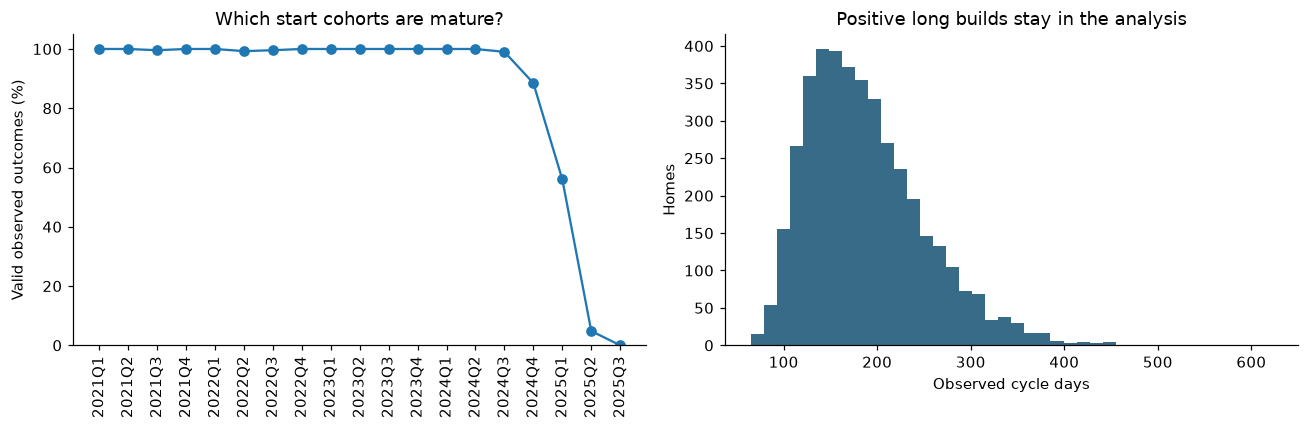

In [36]:
qa = cohort_audit(H)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    qa.index.astype(str),
    qa.valid_pct,
    marker='o',
)
axes[0].set(
    ylabel='Valid observed outcomes (%)',
    title='Which start cohorts are mature?',
    ylim=(0, 105),
)
axes[0].tick_params(axis='x', rotation=90)

axes[1].hist(
    H.loc[H.valid_target, 'cycle_time_days'],
    bins=40,
    color='#376b87',
)
axes[1].set(
    xlabel='Observed cycle days',
    ylabel='Homes',
    title='Positive long builds stay in the analysis',
)

plt.tight_layout()
plt.show()

### Interpretation and limit

The apparent decline in observed duration for recent start cohorts is not evidence that operations suddenly improved. Slow unfinished builds are missing from those averages. A censoring-aware survival model would need a verified observation time and a defensible censoring mechanism, neither of which is available here. Mature-period checks and explicit unscored counts are a cleaner use of the supplied export.

### Feature contract

Features are added in a fixed sequence: specification, geography, start calendar and pre-start process, recent-start pressure, then manager identity. Each step asks whether the extra information improves out-of-time prediction.

Recent-start counts cover the prior 90 days and exclude the forecast home, same-day peers, and future starts. They measure recent incoming volume, not active workload or staffing capacity.

End and inspection dates, final invoices, change orders, and status are excluded as post-start information. `home_id` and `data_source` are not predictors. Lot number is omitted as identifier-like, plan code is used instead of redundant plan name, and untimestamped options value remains outside the eligible final model. Recorded manager assignment is treated as available at start, which should be confirmed with the business.

In [37]:
roster = pd.concat([H, P], ignore_index=True)

HF = start_features(H, roster)
PF = start_features(P, roster)

feature_table = pd.DataFrame([
    {
        'model': name,
        'features': ', '.join(features),
        'count': len(features),
    }
    for name, features in FAMILIES.items()
])

with pd.option_context('display.max_colwidth', None):
    display(feature_table)

# Falsification: future rows and changed outcomes must not change start-day features.
probe = HF.loc[
    HF.construction_start_date.between('2023-08-01', '2023-08-31')
].head(20)

prior_roster = roster.loc[
    roster.construction_start_date < probe.construction_start_date.max()
]

pd.testing.assert_frame_equal(
    start_features(probe, prior_roster)[PRESSURE],
    probe[PRESSURE],
)

mutated = roster.copy()
mutated['construction_end_date'] = pd.Timestamp('2099-01-01')
mutated['cycle_time_days'] = 99999

pd.testing.assert_frame_equal(
    start_features(probe, mutated)[PRESSURE],
    probe[PRESSURE],
)

print(
    'Future starts and changed future outcomes do not affect probe pressure features.'
)

,model,features,count
0,M2_spec,"plan_code, product_line, beds, baths, half_baths, sqft, stories, garage_size_clean, basement_type_clean, lot_type, lot_size_sqft, is_spec_home",12
1,M3_geo,"plan_code, product_line, beds, baths, half_baths, sqft, stories, garage_size_clean, basement_type_clean, lot_type, lot_size_sqft, is_spec_home, community_clean, metro, permit_authority",15
2,M4_time,"plan_code, product_line, beds, baths, half_baths, sqft, stories, garage_size_clean, basement_type_clean, lot_type, lot_size_sqft, is_spec_home, community_clean, metro, permit_authority, start_sin, start_cos, start_year, permit_days, permit_to_start_days, sale_lead_days, sale_recorded",22
3,M5_pressure,"plan_code, product_line, beds, baths, half_baths, sqft, stories, garage_size_clean, basement_type_clean, lot_type, lot_size_sqft, is_spec_home, community_clean, metro, permit_authority, start_sin, start_cos, start_year, permit_days, permit_to_start_days, sale_lead_days, sale_recorded, manager_starts_90d, community_starts_90d",24
4,M6_manager,"plan_code, product_line, beds, baths, half_baths, sqft, stories, garage_size_clean, basement_type_clean, lot_type, lot_size_sqft, is_spec_home, community_clean, metro, permit_authority, start_sin, start_cos, start_year, permit_days, permit_to_start_days, sale_lead_days, sale_recorded, manager_starts_90d, community_starts_90d, site_manager",25


Future starts and changed future outcomes do not affect probe pressure features.


## 4. Development backtests: information before algorithms

Ridge provides a simple additive reference. Its imputation, scaling, and one-hot encoding are fitted inside each training sample. CatBoost is the single nonlinear model because it handles mixed tabular data and interactions without a large hand-built feature expansion. Its depth, learning rate, and number of trees are fixed before the later evaluation period.

Model choice is based on pooled development MAE. If several eligible models are within one day of the best development MAE, the simpler model in the declared order is preferred. The one-day tolerance is a practical simplicity rule, not an estimated business cost threshold.

Three earlier windows expose the models to different operating periods. All scored development outcomes must be known before the August 2024 evaluation origin. These windows are useful stress tests, not independent copies of the 2025 deployment regime.

In [38]:
DEV_WINDOWS = [
    ('2022_AugOct', '2022-08-01', '2022-10-31'),
    ('2023_FebApr', '2023-02-01', '2023-04-30'),
    ('2023_AugOct', '2023-08-01', '2023-10-31'),
]

SPECS = {
    'M0_global': ('global', None),
    'M1_plan': ('plan', None),
    'Ridge': ('ridge', FAMILIES['M6_manager']),
    **{name: ('catboost', features) for name, features in FAMILIES.items()},
}

dev_results, dev_oof, dev_audit = backtest(
    HF,
    DEV_WINDOWS,
    SPECS,
    score_asof='2024-08-01',
)

display(dev_audit)

display(
    dev_results
    .pivot(index='model', columns='fold', values='MAE_days')
    .round(2)
)

pooled = pd.DataFrame({
    name: metrics(dev_oof.cycle_time_days, dev_oof[name])
    for name in SPECS
}).T

preference = ['M0_global', 'M1_plan', 'Ridge', *FAMILIES]

shortlist = set(
    pooled.index[
        pooled.MAE_days <= pooled.MAE_days.min() + 1.0
    ]
)

SELECTED = next(
    name for name in preference
    if name in shortlist
)

display(
    pooled
    .sort_values('MAE_days')
    .round(2)
)

print('Frozen selection:', SELECTED)

,fold,origin,end,train_n,cohort_n,scored_n,not_scored,scored_pct,maturity_days
0,2022_AugOct,2022-08-01,2022-10-31,814,259,258,1,99.61,0
1,2023_FebApr,2023-02-01,2023-04-30,1284,259,259,0,100.00,0
2,2023_AugOct,2023-08-01,2023-10-31,1753,277,272,5,98.19,0


fold,2022_AugOct,2023_AugOct,2023_FebApr
model,,,
M0_global,65.10,47.42,51.04
M1_plan,54.76,31.62,40.94
M2_spec,52.70,30.54,37.75
M3_geo,51.87,30.32,37.25
M4_time,52.42,30.75,31.81
M5_pressure,52.25,31.53,32.06
M6_manager,51.77,32.62,31.79
Ridge,47.67,67.48,51.41


,MAE_days,RMSE_days,bias_days,p90_abs_error,within_30_pct
M4_time,38.18,49.76,-7.32,76.49,47.40
M5_pressure,38.48,50.04,-6.72,76.90,46.51
M6_manager,38.61,49.87,-5.05,75.84,47.40
M3_geo,39.64,52.51,-17.86,82.66,47.53
M2_spec,40.15,53.75,-18.56,83.89,47.40
M1_plan,42.24,56.46,-19.51,87.99,44.99
M0_global,54.39,69.23,-16.63,105.31,32.07
Ridge,55.73,65.68,23.39,100.29,26.74


Frozen selection: M4_time


,addition,relative_to,MAE_gain_days,lo95,hi95,months
0,M3_geo,M2_spec,0.51,-0.43,1.42,9
1,M4_time,M3_geo,1.46,-1.17,4.90,9
2,M5_pressure,M4_time,-0.30,-0.67,0.11,9
3,M6_manager,M5_pressure,-0.13,-0.78,0.47,9


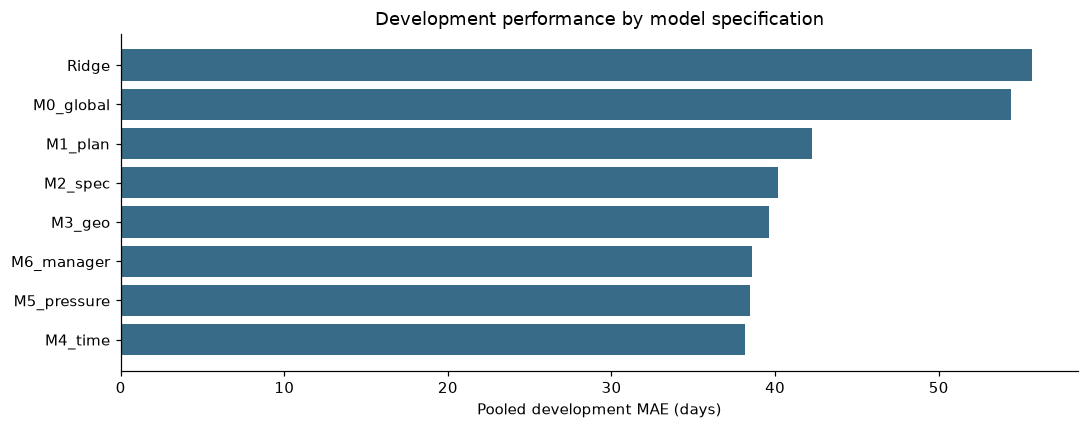

In [39]:
# Incremental information within the fixed CatBoost model class. Positive means improvement.
ablation = []
chain = list(FAMILIES)
blocks = dev_oof["construction_start_date"].dt.to_period("M").astype(str)

for before, after in zip(chain[:-1], chain[1:]):
    gain = (
        (dev_oof["cycle_time_days"] - dev_oof[before]).abs()
        - (dev_oof["cycle_time_days"] - dev_oof[after]).abs()
    )
    average, lower, upper, months = block_mean_interval(gain, blocks)
    
    ablation.append({
        "addition": after,
        "relative_to": before,
        "MAE_gain_days": average,
        "lo95": lower,
        "hi95": upper,
        "months": months,
    })

ablation = pd.DataFrame(ablation)

display(ablation.round(2))

fig, ax = plt.subplots()

ordered = pooled.sort_values("MAE_days")

ax.barh(ordered.index, ordered["MAE_days"], color="#376b87")
ax.set(
    xlabel="Pooled development MAE (days)",
    title="Development performance by model specification",
)

plt.tight_layout()

plt.show()

### Separate model form from added information

The incumbent is a plan-level mean, while `M2_spec` is a nonlinear tree model with additional specification fields. A direct M1-to-M2 gain mixes two changes: model form and information.

To separate them, fit a CatBoost model using only `plan_code`. The plan mean versus plan-only tree comparison isolates model form. The plan-only tree versus `M2_spec` comparison then measures the incremental value of the added specification fields within the same model class.

In [40]:
# Separate model-class improvement from added specification information
tree_plan_spec = {"Tree_plan_only": ("catboost", ["plan_code"])}
_, tree_plan_oof, _ = backtest(
    HF,
    DEV_WINDOWS,
    tree_plan_spec,
    score_asof="2024-08-01",
)

model_form_frame = dev_oof[[
    "home_id",
    "construction_start_date",
    "cycle_time_days",
    "M1_plan",
    "M2_spec",
]].copy()

model_form_frame["Tree_plan_only"] = tree_plan_oof["Tree_plan_only"].to_numpy()

model_form_blocks = model_form_frame["construction_start_date"].dt.to_period("M").astype(str)

decomposition = []
for before, after, label in [
    ("M1_plan", "Tree_plan_only", "Model form: plan mean → plan-only CatBoost"),
    ("Tree_plan_only", "M2_spec", "Information: add project specifications"),
]:
    
    gain = (
        (model_form_frame["cycle_time_days"] - model_form_frame[before]).abs()
        
        - (model_form_frame["cycle_time_days"] - model_form_frame[after]).abs()
    )
    
    average, lower, upper, months = block_mean_interval(gain, model_form_blocks)
    
    decomposition.append({
        "comparison": label,
        "MAE_gain_days": average,
        "lo95": lower,
        "hi95": upper,
        "months": months,
    })

display(pd.DataFrame(decomposition).round(2))

,comparison,MAE_gain_days,lo95,hi95,months
0,Model form: plan mean → plan-only CatBoost,0.23,-0.37,0.91,9
1,Information: add project specifications,1.86,0.96,2.73,9


### What the paired intervals mean

Each comparison uses the same homes for both models and subtracts their absolute errors home by home. The bootstrap resamples calendar months rather than individual rows so homes exposed to the same month-level conditions stay together.

Only nine development months are available, so the intervals are best read as stability checks. They do not fully capture dependence across adjacent months, uncertainty from refitting the models, or the fact that several ablations were examined. Sequential feature gains also depend on the order in which families are added.

In [41]:
incumbent_gain = (
    pooled.loc["M1_plan", "MAE_days"]
    - pooled.loc[SELECTED, "MAE_days"]
)
pressure_gain = ablation.set_index("addition").loc["M5_pressure"]

display(
    Markdown(
        f"**Development result.** `{SELECTED}` improves pooled MAE by "
        f"**{incumbent_gain:.2f} days** versus the floor-plan benchmark. "
        f"Adding recent-start pressure after specification, geography, and time changes "
        f"MAE by **{pressure_gain.MAE_gain_days:.2f} days** "
        f"(month-block interval {pressure_gain.lo95:.2f} to {pressure_gain.hi95:.2f}). "
        "The pressure step does not improve pooled development MAE, so H2 is not supported "
        "by this proxy. That does not show that true workload is unimportant."
    )
)

**Development result.** `M4_time` improves pooled MAE by **4.06 days** versus the floor-plan benchmark. Adding recent-start pressure after specification, geography, and time changes MAE by **-0.30 days** (month-block interval -0.67 to 0.11). The pressure step does not improve pooled development MAE, so H2 is not supported by this proxy. That does not show that true workload is unimportant.

## 5. Falsification checks before the later evaluation

Three checks try to break the development conclusion before looking at the later model score.

**Older-start sensitivity.** Restrict training to homes that started at least 365 days before each forecast origin while still requiring the outcome to be known. This reduces reliance on recently completed fast builds but also throws away current regime information.

**Square-footage sensitivity.** Remove `sqft` entirely. If performance holds, the supported scaling repair is not carrying the result.

**Options diagnostic.** Add `selected_options_value` only in development. Any gain is evidence that the field is worth clarifying, not permission to use an untimestamped feature in the final model.

In [42]:
selected_kind, selected_columns = SPECS[SELECTED]

sensitivity_rows = []

old_r, old_oof, old_audit = backtest(
    HF,
    DEV_WINDOWS,
    {SELECTED: SPECS[SELECTED]},
    maturity_days=365,
    score_asof='2024-08-01',
)

sensitivity_rows.append({
    'experiment': 'Selected / all known completions',
    **metrics(dev_oof.cycle_time_days, dev_oof[SELECTED]),
})

sensitivity_rows.append({
    'experiment': 'Selected / starts aged at least 365 days',
    **metrics(old_oof.cycle_time_days, old_oof[SELECTED]),
})

if selected_columns is not None:
    checks = {
        'Without_sqft': (
            selected_kind,
            [c for c in selected_columns if c != 'sqft'],
        ),
        'Options_DIAGNOSTIC': (
            selected_kind,
            selected_columns + ['selected_options_value'],
        ),
    }

    sens_r, sens_oof, _ = backtest(
        HF,
        DEV_WINDOWS,
        checks,
        score_asof='2024-08-01',
    )

    for name in checks:
        sensitivity_rows.append({
            'experiment': name,
            **metrics(sens_oof.cycle_time_days, sens_oof[name]),
        })

display(pd.DataFrame(sensitivity_rows).round(2))

maturity_audit = []

for fold, origin, end in DEV_WINDOWS:
    origin = pd.Timestamp(origin)

    eligible = (
        HF.construction_start_date
        < origin - pd.Timedelta(days=365)
    )
    known = (
        HF.valid_target
        & (HF.construction_end_date < origin)
    )

    maturity_audit.append({
        'fold': fold,
        'older_starts': eligible.sum(),
        'known_valid_pct': 100 * (eligible & known).sum() / eligible.sum(),
    })

display(pd.DataFrame(maturity_audit))

display(Markdown(
    "**Interpretation.** Older-start training increases development MAE from "
    f"{sensitivity_rows[0]['MAE_days']:.2f} to "
    f"{sensitivity_rows[1]['MAE_days']:.2f} days. "
    "Reducing recent-completion selection trades away information about changing "
    "conditions; these data do not isolate the two mechanisms. Removing square "
    "footage changes MAE only modestly, so the scaling repair is not carrying the "
    "headline. The options diagnostic is retained only as a reason to obtain a "
    "start-day snapshot."
))

,experiment,MAE_days,RMSE_days,bias_days,p90_abs_error,within_30_pct
0,Selected / all known completions,38.18,49.76,-7.32,76.49,47.40
1,Selected / starts aged at least 365 days,41.18,53.90,-12.34,82.78,44.74
2,Without_sqft,38.63,50.27,-6.91,77.85,45.63
3,Options_DIAGNOSTIC,37.45,49.29,-6.74,78.10,48.04


,fold,older_starts,known_valid_pct
0,2022_AugOct,459,99.78
1,2023_FebApr,890,99.55
2,2023_AugOct,1379,99.56


**Interpretation.** Older-start training increases development MAE from 38.18 to 41.18 days. Reducing recent-completion selection trades away information about changing conditions; these data do not isolate the two mechanisms. Removing square footage changes MAE only modestly, so the scaling repair is not carrying the headline. The options diagnostic is retained only as a reason to obtain a start-day snapshot.

## 6. Later August–October 2024 evaluation

The model specification is frozen using the earlier development windows, then refitted at August 1, 2024 using only outcomes known before that date. The same fitted model is scored across August through October.

The floor-plan benchmark uses the identical training cohort. Homes without a valid target are shown separately rather than silently discarded.

This period is later than the development windows, but it is not presented as a completely untouched test because the initial audit already inspected its baseline and target maturity. No model choice or hyperparameter is changed after seeing the results below.

In [43]:
train, hold, hold_audit = temporal_split(
    HF,
    '2024-08-01',
    '2024-10-31',
)

HOLD_MODELS = {
    name: ForecastModel(cols, kind).fit(train)
    for name, (kind, cols) in SPECS.items()
    if name in ['M0_global', 'M1_plan', SELECTED]
}

hold_oof = hold.copy()

for name, model in HOLD_MODELS.items():
    hold_oof[name] = model.predict(hold)

hold_scores = pd.DataFrame({
    name: metrics(hold.cycle_time_days, hold_oof[name])
    for name in HOLD_MODELS
}).T

display(pd.Series(hold_audit).to_frame('value'))
display(hold_scores.round(2))

excluded = HF.loc[
    HF.construction_start_date.between('2024-08-01', '2024-10-31')
    & ~HF.valid_target,
    [
        'home_id',
        'construction_start_date',
        'construction_end_date',
        'construction_status',
        'cycle_time_days',
    ],
]

display(excluded)

gain_hold = (
    hold_scores.loc['M1_plan', 'MAE_days']
    - hold_scores.loc[SELECTED, 'MAE_days']
)

display(Markdown(
    f"**Later-period result:** `{SELECTED}` MAE is "
    f"**{hold_scores.loc[SELECTED, 'MAE_days']:.2f} days**, versus "
    f"**{hold_scores.loc['M1_plan', 'MAE_days']:.2f} days** for the incumbent, "
    f"a **{gain_hold:.2f}-day** improvement "
    f"({100 * gain_hold / hold_scores.loc['M1_plan', 'MAE_days']:.1f}%). "
    f"Mean signed error is **{hold_scores.loc[SELECTED, 'bias_days']:.2f} days**; "
    "positive values mean the forecast is longer than the actual duration."
))

,value
origin,2024-08-01 00:00:00
end,2024-10-31 00:00:00
train_n,2938
cohort_n,291
scored_n,287
not_scored,4
scored_pct,98.63
maturity_days,0


,MAE_days,RMSE_days,bias_days,p90_abs_error,within_30_pct
M0_global,48.41,56.34,37.79,87.63,31.71
M1_plan,36.42,44.84,30.03,75.01,49.83
M4_time,21.41,28.22,-9.39,44.14,75.26


,home_id,construction_start_date,construction_end_date,construction_status,cycle_time_days
1117,H103515,2024-08-10,2024-08-08,Complete,-2.00
2585,H103672,2024-09-29,NaT,In Progress,NaN
3713,H103689,2024-10-01,2024-09-27,Complete,-4.00
4099,H103493,2024-08-04,NaT,In Progress,NaN


**Later-period result:** `M4_time` MAE is **21.41 days**, versus **36.42 days** for the incumbent, a **15.01-day** improvement (41.2%). Mean signed error is **-9.39 days**; positive values mean the forecast is longer than the actual duration.

### Can the four unscored homes reverse the comparison?

Their absolute errors cannot be calculated without valid outcomes. However, for any possible actual duration, the difference between two absolute errors is bounded by the distance between the two forecasts.

Applying that bound to each unscored home gives a worst-case range for the full-cohort MAE difference without imputing a target. It does not bound either model's absolute MAE and does not solve training-selection bias.

In [44]:
all_hold = HF.loc[
    HF.construction_start_date.between('2024-08-01', '2024-10-31')
].copy()

unscored_hold = all_hold.loc[~all_hold.valid_target]

known_gain = (
    (hold_oof.cycle_time_days - hold_oof.M1_plan).abs()
    - (hold_oof.cycle_time_days - hold_oof[SELECTED]).abs()
).sum()

unknown_gap = np.abs(
    HOLD_MODELS['M1_plan'].predict(unscored_hold)
    - HOLD_MODELS[SELECTED].predict(unscored_hold)
).sum()

full_gain_bounds = (
    (known_gain - unknown_gap) / len(all_hold),
    (known_gain + unknown_gap) / len(all_hold),
)

display(
    pd.Series({
        'all_starts': len(all_hold),
        'unscored': len(unscored_hold),
        'full_cohort_MAE_gain_lower_days': full_gain_bounds[0],
        'full_cohort_MAE_gain_upper_days': full_gain_bounds[1],
    }).to_frame('value')
)

display(Markdown(
    "Even allowing arbitrary valid durations for those homes, the full-cohort "
    f"gain lies between **{full_gain_bounds[0]:.2f} and "
    f"{full_gain_bounds[1]:.2f} days**. A strictly positive lower bound means "
    "their missing outcomes alone cannot reverse this comparison. It does not "
    "remove selection bias in training or establish transportability to 2025."
))

,value
all_starts,291.00
unscored,4.00
full_cohort_MAE_gain_lower_days,14.50
full_cohort_MAE_gain_upper_days,15.10


Even allowing arbitrary valid durations for those homes, the full-cohort gain lies between **14.50 and 15.10 days**. A strictly positive lower bound means their missing outcomes alone cannot reverse this comparison. It does not remove selection bias in training or establish transportability to 2025.

### Forecast uncertainty: empirical 90% error bands

A point forecast is not enough for scheduling risk. The notebook takes the 90th percentile of absolute development errors and applies that allowance around the later-period point forecast, with the lower end truncated at one day.

This is an empirical planning band, not a distribution-free conformal guarantee. Models are refitted across origins, observations are time-dependent, and the regime can change. Its usefulness is judged by later coverage and width, not by the nominal 90% label alone.

,value
nominal_coverage_pct,90.00
empirical_holdout_coverage_pct,97.56
mean_width_days,153.43
allowance_days,76.71
actual_above_upper_pct,2.09


,n,coverage
month,,
2024-08,89,0.97
2024-09,111,0.97
2024-10,87,0.99


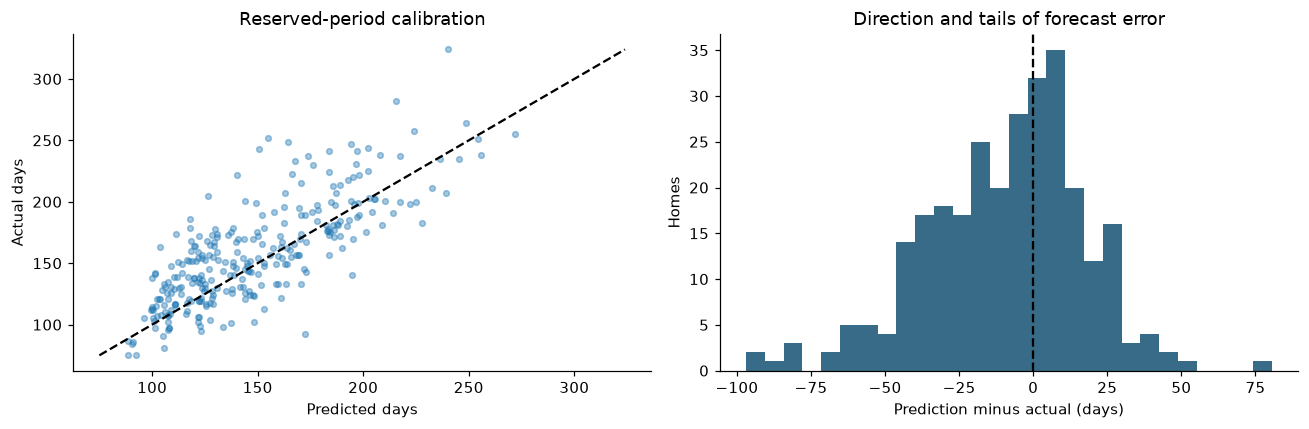

**Use with care.** Coverage is **97.6%**, above the nominal 90%, but the average width is **153.4 days**. Errors from the more difficult earlier regimes make this a conservative, broad planning allowance. It is too imprecise to present as a reliable closing commitment. The later period is not used to shrink it.

In [45]:
cal_errors = (
    dev_oof.cycle_time_days - dev_oof[SELECTED]
).abs().to_numpy()

allowance = float(
    np.quantile(cal_errors, .90, method='higher')
)

hold_oof['lower90'] = np.maximum(
    1,
    hold_oof[SELECTED] - allowance,
)

hold_oof['upper90'] = (
    hold_oof[SELECTED] + allowance
)

hold_oof['covered90'] = (
    hold_oof.cycle_time_days
    .between(hold_oof.lower90, hold_oof.upper90)
)

interval_summary = pd.Series({
    'nominal_coverage_pct': 90,
    'empirical_holdout_coverage_pct': 100 * hold_oof.covered90.mean(),
    'mean_width_days': (
        hold_oof.upper90 - hold_oof.lower90
    ).mean(),
    'allowance_days': allowance,
    'actual_above_upper_pct': 100 * (
        hold_oof.cycle_time_days > hold_oof.upper90
    ).mean(),
})

display(
    interval_summary.to_frame('value')
)

# A three-month holdout cannot support a precise time-dependence-robust coverage CI.
held_month = (
    hold_oof.construction_start_date
    .dt.to_period('M')
)

display(
    hold_oof
    .assign(month=held_month)
    .groupby('month')
    .agg(
        n=('home_id', 'size'),
        coverage=('covered90', 'mean'),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    hold_oof[SELECTED],
    hold_oof.cycle_time_days,
    alpha=.4,
    s=14,
)

bounds = [
    min(
        hold_oof[SELECTED].min(),
        hold_oof.cycle_time_days.min(),
    ),
    max(
        hold_oof[SELECTED].max(),
        hold_oof.cycle_time_days.max(),
    ),
]

axes[0].plot(
    bounds,
    bounds,
    color='black',
    linestyle='--',
)

axes[0].set(
    xlabel='Predicted days',
    ylabel='Actual days',
    title='Reserved-period calibration',
)

axes[1].hist(
    hold_oof[SELECTED] - hold_oof.cycle_time_days,
    bins=28,
    color='#376b87',
)

axes[1].axvline(
    0,
    color='black',
    linestyle='--',
)

axes[1].set(
    xlabel='Prediction minus actual (days)',
    ylabel='Homes',
    title='Direction and tails of forecast error',
)

plt.tight_layout()
plt.show()

display(Markdown(
    f"**Use with care.** Coverage is "
    f"**{interval_summary.empirical_holdout_coverage_pct:.1f}%**, "
    "above the nominal 90%, but the average width is "
    f"**{interval_summary.mean_width_days:.1f} days**. "
    "Errors from the more difficult earlier regimes make this a conservative, "
    "broad planning allowance. It is too imprecise to present as a reliable "
    "closing commitment. The later period is not used to shrink it."
))

## 7. Error analysis and attempts to break the headline

Overall MAE can hide where a model fails. Errors are therefore checked by metro, month, plan support, project size, recent-start pressure, and community. Segment boundaries come from the training sample.

Two additional diagnostics test whether the headline depends on a small part of the data: remove the longest 5% of scored builds, and recompute the aggregate gain while leaving out each community in turn. These checks do not change the fitted model or the primary score.

In [46]:
hold_oof['month'] = hold_oof.construction_start_date.dt.strftime('%Y-%m')

plan_counts = train.plan_code.value_counts()

hold_oof['plan_support'] = np.where(
    ~hold_oof.plan_code.isin(plan_counts.index),
    'unseen',
    np.where(
        hold_oof.plan_code.map(plan_counts).fillna(0) < 30,
        'rare (<30 training homes)',
        'seen (>=30)',
    ),
)

size_cuts = [
    -np.inf,
    *train.sqft.quantile([.33, .67]).unique(),
    np.inf,
]

pressure_cuts = [
    -np.inf,
    *train.manager_starts_90d.quantile([.33, .67]).unique(),
    np.inf,
]

hold_oof['size_band'] = pd.cut(
    HOLD_MODELS[SELECTED].repair_.transform(hold).sqft
    if selected_columns else hold.sqft,
    size_cuts,
    duplicates='drop',
)

hold_oof['pressure_band'] = pd.cut(
    hold_oof.manager_starts_90d,
    pressure_cuts,
    duplicates='drop',
)

for group in [
    'metro',
    'month',
    'plan_support',
    'size_band',
    'pressure_band',
]:
    print(group)
    display(
        segment_errors(
            hold_oof,
            SELECTED,
            'M1_plan',
            group,
        ).round(2)
    )

print('Community coverage and errors (small groups are unstable):')

display(
    segment_errors(
        hold_oof,
        SELECTED,
        'M1_plan',
        'community_clean',
    )
    .sort_values('MAE_days', ascending=False)
    .round(2)
)

robustness = []

for label, mask in [
    (
        'All scored homes',
        np.ones(len(hold_oof), dtype=bool),
    ),
    (
        'Exclude longest 5% (diagnostic)',
        hold_oof.cycle_time_days
        <= hold_oof.cycle_time_days.quantile(.95),
    ),
]:
    d = hold_oof.loc[mask]

    robustness.append({
        'sample': label,
        'n': len(d),
        'selected_MAE': metrics(
            d.cycle_time_days,
            d[SELECTED],
        )['MAE_days'],
        'plan_MAE': metrics(
            d.cycle_time_days,
            d.M1_plan,
        )['MAE_days'],
    })

display(pd.DataFrame(robustness))

loo = []

for community in hold_oof.community_clean.unique():
    d = hold_oof.loc[
        hold_oof.community_clean != community
    ]

    loo.append({
        'excluded_community': community,
        'MAE_gain_days': (
            (d.cycle_time_days - d.M1_plan).abs().mean()
            - (d.cycle_time_days - d[SELECTED]).abs().mean()
        ),
    })

display(
    pd.DataFrame(loo)
    .sort_values('MAE_gain_days')
)

metro


,n,MAE_days,baseline_MAE,bias_days,p90_abs_error
metro,,,,,
Calgary,90,24.09,32.61,-13.10,50.52
Denver,108,19.61,29.12,-9.90,41.00
Edmonton,89,20.89,49.12,-5.01,44.65


month


,n,MAE_days,baseline_MAE,bias_days,p90_abs_error
month,,,,,
2024-08,89,21.10,39.43,-8.34,40.88
2024-09,111,22.05,36.46,-9.07,44.89
2024-10,87,20.92,33.28,-10.86,43.65


plan_support


,n,MAE_days,baseline_MAE,bias_days,p90_abs_error
plan_support,,,,,
seen (>=30),287,21.41,36.42,-9.39,44.14


... (4 outputs left out)

Community coverage and errors (small groups are unstable):


,n,MAE_days,baseline_MAE,bias_days,p90_abs_error
community_clean,,,,,
auburn meadows,15,32.68,27.90,-27.79,63.58
riverbend,15,28.47,30.75,-24.09,57.22
windermere,22,26.91,35.72,-20.50,61.80
cranston ridge,13,25.72,25.79,-17.52,60.94
sterling ranch,14,24.30,33.77,-13.63,49.94
legacy gate,20,23.58,30.34,-9.34,43.88
laurel green,23,23.19,53.60,-4.36,43.92
barefoot lakes,24,21.10,36.84,-13.74,40.37
aurora highlands,25,19.03,24.15,-11.81,39.63


,sample,n,selected_MAE,plan_MAE
0,All scored homes,287,21.41,36.42
1,Exclude longest 5% (diagnostic),272,19.88,37.10


,excluded_community,MAE_gain_days
12,glenridding,12.26
3,laurel green,13.66
9,mahogany point,13.99
10,keswick landing,14.09
6,barefoot lakes,14.94
4,green valley,15.00
13,sterling ranch,15.29
7,windermere,15.52
1,legacy gate,15.62
11,riverbend,15.71


## 8. Manager comparisons

### Estimand

For each manager, compare actual duration with an out-of-time expected duration for the projects they received. Negative residuals mean builds finished faster than the no-manager model expected after centering common forecast bias within each evaluation period. This is an adjusted association, not the causal effect of assigning a home to that manager.

### Method

The main adjustment uses `M5_pressure`, which excludes manager identity. `M4_time`, which also omits recent-start pressure, is reported as an alternative because pressure may partly reflect assignment. Raw and adjusted comparisons use the same evaluated homes. Uncertainty is estimated by resampling start months within manager.

### Limits

The adjustment can only account for recorded project characteristics. Crews, staffing, reassignment, site difficulty, and manager-assignment rules are not observed. The intervals are marginal across 18 managers, use only nine development months, and condition on fitted expected-duration models. Picking the smallest estimate also creates winner's bias, so small rank differences are not treated as proof of a unique best manager.

,n,months,raw_days,adjusted_days,lo95,hi95,alternative_days,communities,plans,raw_rank,adjusted_rank
site_manager,,,,,,,,,,,
W. Halvorsen,38,9,220.74,-13.36,-26.20,5.19,-14.70,14,12,16.00,1.00
R. Ivanova,50,9,199.92,-9.79,-17.45,-0.07,-10.11,14,15,12.00,2.00
L. Mwangi,45,9,189.60,-8.94,-17.72,0.48,-9.16,13,16,4.00,3.00
N. Ferreira,35,8,199.11,-7.46,-23.77,6.27,-7.09,13,15,10.00,4.00
P. Sandoval,33,9,199.73,-7.35,-21.48,5.47,-5.90,12,14,11.00,5.00
V. Okonkwo,58,9,231.84,-3.97,-17.99,6.83,-5.27,14,14,18.00,6.00
S. Ahmadi,52,9,208.00,-3.73,-7.82,0.76,-5.06,13,15,13.00,7.00
M. Petrov,50,9,194.72,-3.51,-13.67,7.01,-2.75,12,16,7.00,8.00
T. Beaulieu,47,9,220.87,-1.49,-13.27,9.53,-0.72,13,15,17.00,9.00


fold,2022_AugOct,2023_AugOct,2023_FebApr
site_manager,,,
W. Halvorsen,-17.91,-22.38,6.53
R. Ivanova,-3.00,-4.14,-19.90
L. Mwangi,-10.94,-1.84,-13.84
N. Ferreira,1.35,-2.34,-32.56
P. Sandoval,1.62,-7.75,-11.87
V. Okonkwo,-1.37,-11.66,0.54
S. Ahmadi,-2.99,-5.28,-2.54
M. Petrov,-10.63,1.82,-1.61
T. Beaulieu,-4.80,7.63,-10.03


Raw vs adjusted rank Spearman correlation: -0.3973168214654283


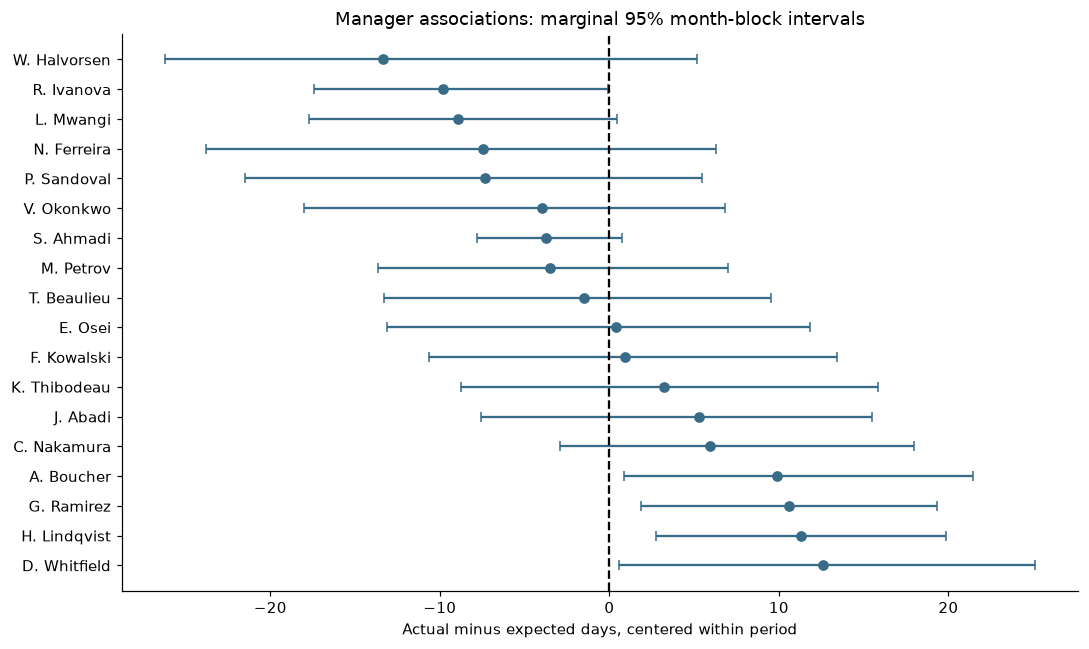

**Answer for Operations.** `A. Boucher` has the lowest raw mean in the evaluated sample. `W. Halvorsen` has the lowest adjusted mean, **-13.36 days** relative to period-centered expectation (marginal interval **-26.20 to 5.19**, **38 homes**). This identifies a candidate for process review, not a causally best manager. Review the alternative adjustment and fold table before acting.

,n,actual_days,expected_without_manager,spec_share,single_family_share
site_manager,,,,,
W. Halvorsen,38,220.74,229.17,0.18,0.89
R. Ivanova,50,199.92,204.06,0.16,0.62
L. Mwangi,45,189.60,192.50,0.22,0.60
N. Ferreira,35,199.11,190.39,0.23,0.54
P. Sandoval,33,199.73,204.26,0.30,0.61
V. Okonkwo,58,231.84,225.74,0.19,0.86
S. Ahmadi,52,208.00,200.17,0.25,0.71
M. Petrov,50,194.72,190.73,0.22,0.48
T. Beaulieu,47,220.87,215.52,0.28,0.83


Raw fastest **A. Boucher** has predicted project-mix duration 160.8 days, versus 229.2 days for adjusted-fastest **W. Halvorsen**. The expected durations and sales/product mix show why raw averages compare different assignments; they do not validate every part of the adjustment model.

In [47]:
managers, manager_rows = manager_summary(
    dev_oof,
    'M5_pressure',
    'M4_time',
)

display(managers.round(2))

stability = (
    manager_rows
    .groupby(['site_manager', 'fold'])
    .residual.mean()
    .unstack()
)

display(stability.loc[managers.index].round(2))

rank_corr = (
    managers[['raw_rank', 'adjusted_rank']]
    .corr(method='spearman')
    .iloc[0, 1]
)

print(
    'Raw vs adjusted rank Spearman correlation:',
    rank_corr,
)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(managers))

ax.errorbar(
    managers.adjusted_days,
    y,
    xerr=[
        managers.adjusted_days - managers.lo95,
        managers.hi95 - managers.adjusted_days,
    ],
    fmt='o',
    color='#376b87',
    capsize=3,
)

ax.set_yticks(y, managers.index)
ax.invert_yaxis()
ax.axvline(0, color='black', linestyle='--')

ax.set(
    xlabel='Actual minus expected days, centered within period',
    title='Manager associations: marginal 95% month-block intervals',
)

plt.tight_layout()
plt.show()

fast = managers.index[0]
raw_fast = managers.raw_days.idxmin()

display(Markdown(
    f"**Answer for Operations.** `{raw_fast}` has the lowest raw mean in the "
    f"evaluated sample. `{fast}` has the lowest adjusted mean, "
    f"**{managers.loc[fast, 'adjusted_days']:.2f} days** relative to "
    f"period-centered expectation (marginal interval "
    f"**{managers.loc[fast, 'lo95']:.2f} to {managers.loc[fast, 'hi95']:.2f}**, "
    f"**{int(managers.loc[fast, 'n'])} homes**). This identifies a candidate "
    "for process review, not a causally best manager. Review the alternative "
    "adjustment and fold table before acting."
))

manager_mix = manager_rows.groupby('site_manager').agg(
    n=('home_id', 'size'),
    actual_days=('cycle_time_days', 'mean'),
    expected_without_manager=('M5_pressure', 'mean'),
    spec_share=('is_spec_home', 'mean'),
    single_family_share=(
        'product_line',
        lambda s: s.eq('Single Family').mean(),
    ),
)

display(
    manager_mix.loc[managers.index]
    .round(2)
)

display(Markdown(
    f"Raw fastest **{raw_fast}** has predicted project-mix duration "
    f"{manager_mix.loc[raw_fast, 'expected_without_manager']:.1f} days, versus "
    f"{manager_mix.loc[fast, 'expected_without_manager']:.1f} days for "
    f"adjusted-fastest **{fast}**. The expected durations and sales/product mix "
    "show why raw averages compare different assignments; they do not validate "
    "every part of the adjustment model."
))

### Later-period stability and a direct comparison

The same no-manager specifications are refitted at the August 2024 origin to see whether manager residual patterns persist in the later period. This check does not affect forecasting-model selection.

For the two lowest development adjusted means, a joint month-block bootstrap estimates their difference directly. An interval spanning zero means the data do not reliably separate the pair. Even a nonzero association would still not establish causality or a unique winner across all managers.

In [48]:
mgr_hold = hold.copy()

for name in ['M5_pressure', 'M4_time']:
    mgr_hold[name] = (
        ForecastModel(FAMILIES[name], 'catboost')
        .fit(train)
        .predict(hold)
    )

mgr_hold['fold'] = '2024_AugOct'

late_managers, _ = manager_summary(
    mgr_hold,
    'M5_pressure',
    'M4_time',
)

manager_compare = (
    managers[['n', 'adjusted_days', 'alternative_days']]
    .join(
        late_managers[['n', 'adjusted_days']]
        .add_prefix('holdout_')
    )
)

display(manager_compare.round(2))

# Joint block bootstrap preserves common calendar shocks between compared managers.
a, b = managers.index[:2]

months = sorted(manager_rows.month.unique())

stats = (
    manager_rows
    .groupby(['month', 'site_manager'])
    .residual
    .agg(['sum', 'count'])
)

rng = np.random.default_rng(SEED)
ix = rng.integers(
    0,
    len(months),
    size=(2000, len(months)),
)

boot_means = []

for manager in [a, b]:
    st = (
        stats
        .xs(manager, level='site_manager')
        .reindex(months, fill_value=0)
    )

    boot_means.append(
        st['sum'].to_numpy()[ix].sum(1)
        / st['count'].to_numpy()[ix].sum(1)
    )

diff = boot_means[0] - boot_means[1]

display(
    pd.Series({
        'comparison': f'{a} minus {b}',
        'difference_days': (
            managers.loc[a, 'adjusted_days']
            - managers.loc[b, 'adjusted_days']
        ),
        'lo95': np.quantile(diff, .025),
        'hi95': np.quantile(diff, .975),
    }).to_frame('value')
)

display(Markdown(
    f"The difference interval **{np.quantile(diff, .025):.1f} to "
    f"{np.quantile(diff, .975):.1f} days** spans zero. "
    f"We cannot reliably separate **{a}** from **{b}**. "
    f"{a}'s later adjusted residual is "
    f"**{manager_compare.loc[a, 'holdout_adjusted_days']:.1f} days** "
    f"on just **{int(manager_compare.loc[a, 'holdout_n'])} homes**. "
    "The direction repeats, but this small check does not establish a stable rank."
))

,n,adjusted_days,alternative_days,holdout_n,holdout_adjusted_days
site_manager,,,,,
W. Halvorsen,38,-13.36,-14.70,13,-19.31
R. Ivanova,50,-9.79,-10.11,18,-3.07
L. Mwangi,45,-8.94,-9.16,11,-14.84
N. Ferreira,35,-7.46,-7.09,10,-9.86
P. Sandoval,33,-7.35,-5.90,20,-18.25
V. Okonkwo,58,-3.97,-5.27,16,2.42
S. Ahmadi,52,-3.73,-5.06,17,-0.86
M. Petrov,50,-3.51,-2.75,12,4.86
T. Beaulieu,47,-1.49,-0.72,19,-4.76


,value
comparison,W. Halvorsen minus R. Ivanova
difference_days,-3.57
lo95,-23.12
hi95,19.80


The difference interval **-23.1 to 19.8 days** spans zero. We cannot reliably separate **W. Halvorsen** from **R. Ivanova**. W. Halvorsen's later adjusted residual is **-19.3 days** on just **13 homes**. The direction repeats, but this small check does not establish a stable rank.

## 9. Which observed characteristics are associated with duration?

Predictive ablations show whether information helps forecasting, but not the direction or adjusted size of a relationship. A separate additive regression is therefore fitted on valid completed homes starting through October 2024. It controls for plan, community, start quarter, manager, lot and basement characteristics, and pre-start process measures.

The reported units are chosen for interpretation: 500 sqft, 10 permit days, 10 recent manager starts, and spec-home status. Month-clustered standard errors allow homes starting in the same month to share shocks. They do not remove omitted-variable bias, nonlinear misspecification, or selection from unfinished outcomes.

This regression is descriptive, not a second forecasting model. Alternative specifications remove manager/pressure terms and restrict the sample to 2023 onward. Full-rank checks guard against redundant coefficient columns.

In [49]:
import statsmodels.formula.api as smf
from src.features import SqftRepair

infer = HF.loc[
    HF.valid_target
    & (HF.construction_start_date <= '2024-10-31')
].copy()

infer = SqftRepair().fit(infer).transform(infer)

infer['sqft_500'] = infer.sqft / 500
infer['permit_10'] = infer.permit_days / 10
infer['pressure_10'] = infer.manager_starts_90d / 10
infer['community_pressure_10'] = infer.community_starts_90d / 10
infer['quarter'] = infer.construction_start_date.dt.to_period('Q').astype(str)
infer['month'] = infer.construction_start_date.dt.to_period('M').astype(str)
infer['spec'] = infer.is_spec_home.astype(int)

controls = [
    'sqft_500',
    'permit_10',
    'pressure_10',
    'community_pressure_10',
    'lot_size_sqft',
    'garage_size_clean',
    'sale_lead_days',
    'permit_to_start_days',
    'beds',
    'baths',
    'half_baths',
    'stories',
]

missing_terms = []

for col in controls:
    if infer[col].isna().any():
        infer[col + '_missing'] = infer[col].isna().astype(int)
        missing_terms.append(col + '_missing')

    infer[col] = infer[col].fillna(infer[col].median())

# Plan absorbs structural bed/bath/stories mix; use a restrained full-rank adjustment.
formula = (
    'cycle_time_days ~ C(plan_code) + C(community_clean) + C(quarter) + C(site_manager)'
    ' + sqft_500 + permit_10 + pressure_10 + community_pressure_10 + spec'
    ' + lot_size_sqft + C(basement_type_clean) + C(lot_type)'
    ' + sale_lead_days + permit_to_start_days'
)

used_missing = [
    col for col in missing_terms
    if col.removesuffix('_missing') in [
        'lot_size_sqft',
        'sale_lead_days',
        'permit_10',
        'permit_to_start_days',
        'sqft_500',
        'garage_size_clean',
    ]
]

if used_missing:
    formula += ' + ' + ' + '.join(used_missing)

fits = {}

fits['adjusted'] = smf.ols(
    formula,
    infer,
).fit(
    cov_type='cluster',
    cov_kwds={'groups': infer.month},
)

alt_formula = (
    formula
    .replace(' + C(site_manager)', '')
    .replace(' + pressure_10', '')
    .replace(' + community_pressure_10', '')
)

fits['without_manager_or_pressure'] = smf.ols(
    alt_formula,
    infer,
).fit(
    cov_type='cluster',
    cov_kwds={'groups': infer.month},
)

late = infer.loc[
    infer.construction_start_date >= '2023-01-01'
]

fits['2023_onward'] = smf.ols(
    formula,
    late,
).fit(
    cov_type='cluster',
    cov_kwds={'groups': late.month},
)

terms = [
    'sqft_500',
    'permit_10',
    'pressure_10',
    'spec',
]

associations = []

for name, fit in fits.items():
    ci = fit.conf_int()

    for term in terms:
        if term in fit.params:
            associations.append({
                'specification': name,
                'term': term,
                'days': fit.params[term],
                'lo95': ci.loc[term, 0],
                'hi95': ci.loc[term, 1],
            })

display(
    pd.DataFrame(associations)
    .round(2)
)

print(
    'Main fit homes / start-month clusters:',
    len(infer),
    infer.month.nunique(),
)

print(
    'Design columns / matrix rank:',
    fits['adjusted'].model.exog.shape[1],
    np.linalg.matrix_rank(fits['adjusted'].model.exog),
)

for name, fit in fits.items():
    assert (
        np.linalg.matrix_rank(fit.model.exog)
        == fit.model.exog.shape[1]
    ), f'Redundant columns in {name}'

print('All three inference designs have full column rank.')

,specification,term,days,lo95,hi95
0,adjusted,sqft_500,24.55,18.54,30.56
1,adjusted,permit_10,0.29,-0.14,0.72
2,adjusted,pressure_10,-3.44,-6.90,0.02
3,adjusted,spec,-37.26,-41.88,-32.64
4,without_manager_or_pressure,sqft_500,21.94,16.40,27.47
5,without_manager_or_pressure,permit_10,0.42,-0.06,0.89
6,without_manager_or_pressure,spec,-35.07,-39.73,-30.42
7,2023_onward,sqft_500,25.00,17.19,32.82
8,2023_onward,permit_10,0.46,-0.07,1.00
9,2023_onward,pressure_10,1.85,-1.65,5.35


Main fit homes / start-month clusters: 3762 46
Design columns / matrix rank: 75 75
All three inference designs have full column rank.


### Operational interpretation

Coefficients are read in their stated units and conditional on the included controls. An interval spanning zero does not distinguish a positive from a negative association under that specification. None of these estimates should be read as an intervention effect.

The most stable findings are the positive within-plan size association and shorter observed durations for spec homes. Permit-time intervals include zero, and the recent-start pressure estimate changes direction in the later sample. That is not strong evidence for permitting or recent-start volume as established operational drivers.

The practical use of these estimates is to identify questions worth testing prospectively. Before changing manager assignments or capacity rules, the business would need start-day records of crews, reassignment, actual active workload, and intervention timing.

## 10. Final refit and the 578 requested predictions

The frozen specification is refitted using every valid historical outcome known before August 1, 2025. No prediction-set outcome is used. For later prediction rows, recent-start features assume earlier listed starts have occurred as recorded; a production system should replace that batch ledger with actual observed starts as time advances.

The final section checks category support, numerical extrapolation, and prediction sensitivity to the recent-cohort selection problem. The selected tree model cannot smoothly extrapolate a new year trend, and only a selected subset of early-2025 homes has completed. Development error bands are therefore carried forward only as a planning reference, not as verified 2025 coverage.

In [50]:
final_train = HF.loc[
    HF['valid_target']
    & (HF['construction_end_date'] < DEPLOYMENT_ORIGIN)
].copy()

assert (
    final_train['construction_end_date'].max()
    < PF['construction_start_date'].min()
)

final_model = ForecastModel(
    selected_columns,
    selected_kind,
).fit(final_train)

final_values = final_model.predict(PF)

predictions = pd.DataFrame({
    'home_id': P['home_id'],
    'predicted_cycle_days': np.round(final_values, 2),
})

assert_prediction_contract(predictions, P)

print('Training homes:', len(final_train))
print('Prediction rows:', len(predictions))

display(predictions.head(10))
display(
    predictions['predicted_cycle_days']
    .describe()
    .to_frame()
)

support = []

for column in [
    'plan_code',
    'community_clean',
    'site_manager',
    'basement_type_clean',
]:
    counts = final_train[column].value_counts()

    support.append({
        'field': column,
        'unseen_prediction_rows': int(
            (~PF[column].isin(counts.index)).sum()
        ),
        'prediction_rows_training_count_under30': int(
            (PF[column].map(counts).fillna(0) < 30).sum()
        ),
    })

display(pd.DataFrame(support))

shift = []

final_train_repaired = final_model.repair_.transform(final_train)
prediction_repaired = final_model.repair_.transform(PF)

for column in [
    'sqft',
    'permit_days',
    'manager_starts_90d',
    'community_starts_90d',
    'start_year',
]:
    shift.append({
        'feature': column,
        'training_median': final_train_repaired[column].median(),
        'prediction_median': prediction_repaired[column].median(),
        'training_min': final_train_repaired[column].min(),
        'training_max': final_train_repaired[column].max(),
        'prediction_outside_training_range_pct': 100 * (
            final_train_repaired[column].min()
            > prediction_repaired[column]
        ).mean() + 100 * (
            prediction_repaired[column]
            > final_train_repaired[column].max()
        ).mean(),
    })

display(pd.DataFrame(shift))

forecast_reference = predictions.assign(
    lower_reference=np.maximum(
        1,
        final_values - allowance,
    ),
    upper_reference=final_values + allowance,
)

display(forecast_reference.head())

Training homes: 4077
Prediction rows: 578


,home_id,predicted_cycle_days
0,H105165,109.51
1,H105228,125.62
2,H104895,121.93
3,H105114,123.62
4,H105155,180.23
5,H104917,194.97
6,H105019,157.52
7,H104800,158.78
8,H105143,128.31
9,H105002,153.59


,predicted_cycle_days
count,578.00
mean,143.28
std,37.22
min,79.21
25%,114.63
50%,134.17
75%,170.15
max,267.77


,field,unseen_prediction_rows,prediction_rows_training_count_under30
0,plan_code,0,0
1,community_clean,0,0
2,site_manager,0,0
3,basement_type_clean,0,0


,feature,training_median,prediction_median,training_min,training_max,prediction_outside_training_range_pct
0,sqft,"1,950.00","1,680.00","1,050.00","3,780.00",0.00
1,permit_days,39.00,40.00,6.00,210.00,0.00
2,manager_starts_90d,13.00,21.00,0.00,30.00,2.60
3,community_starts_90d,18.00,25.00,0.00,33.00,7.96
4,start_year,"2,023.00","2,025.00","2,021.00","2,025.00",0.00


,home_id,predicted_cycle_days,lower_reference,upper_reference
0,H105165,109.51,32.79,186.22
1,H105228,125.62,48.90,202.33
2,H104895,121.93,45.22,198.64
3,H105114,123.62,46.90,200.33
4,H105155,180.23,103.52,256.95


### Deployment sensitivity to recent-cohort selection

The final training set contains all valid outcomes known before August 2025, but recent start cohorts are selectively complete: fast builds are more likely to have finished. Because the selected model includes `start_year`, a tree could partly learn that selected recent completions are unusually short.

Two diagnostics test how much the 578 forecasts depend on that choice without changing the frozen primary model:

1. refit the same M4 feature family without `start_year`;
2. refit M4 using only homes that started at least 365 days before deployment.

The comparison reports how far those alternative predictions move from the primary forecast. Large shifts would be a deployment warning even if the historical holdout result remains strong.

In [51]:
# Stress-test final predictions against recent-cohort selection.
no_year_columns = [
    column for column in selected_columns
    if column != 'start_year'
]

no_year_model = ForecastModel(
    no_year_columns,
    selected_kind,
).fit(final_train)

no_year_values = no_year_model.predict(PF)

mature_cutoff = (
    DEPLOYMENT_ORIGIN - pd.Timedelta(days=365)
)

mature_final_train = final_train.loc[
    final_train['construction_start_date'] < mature_cutoff
].copy()

mature_model = ForecastModel(
    selected_columns,
    selected_kind,
).fit(mature_final_train)

mature_values = mature_model.predict(PF)

# Historical context: neither alternative is allowed to silently replace the frozen model.
no_year_hold_model = ForecastModel(
    no_year_columns,
    selected_kind,
).fit(train)

no_year_hold_values = no_year_hold_model.predict(hold)

old_hold_train, old_hold, _ = temporal_split(
    HF,
    '2024-08-01',
    '2024-10-31',
    maturity_days=365,
)

old_hold_model = ForecastModel(
    selected_columns,
    selected_kind,
).fit(old_hold_train)

old_hold_values = old_hold_model.predict(old_hold)

primary_hold_mae = hold_scores.loc[SELECTED, 'MAE_days']

no_year_hold_mae = metrics(
    hold['cycle_time_days'],
    no_year_hold_values,
)['MAE_days']

old_hold_mae = metrics(
    old_hold['cycle_time_days'],
    old_hold_values,
)['MAE_days']


def prediction_shift_summary(
    label,
    alternative,
    training_n,
    historical_mae,
):
    difference = np.abs(alternative - final_values)

    return {
        'sensitivity': label,
        'training_n': training_n,
        'historical_2024_MAE': historical_mae,
        'mean_prediction_days': alternative.mean(),
        'median_abs_shift_days': np.median(difference),
        'p90_abs_shift_days': np.quantile(difference, 0.90),
        'max_abs_shift_days': difference.max(),
    }


deployment_sensitivity = pd.DataFrame([
    {
        'sensitivity': 'Primary M4',
        'training_n': len(final_train),
        'historical_2024_MAE': primary_hold_mae,
        'mean_prediction_days': final_values.mean(),
        'median_abs_shift_days': 0.0,
        'p90_abs_shift_days': 0.0,
        'max_abs_shift_days': 0.0,
    },
    prediction_shift_summary(
        'M4 without start_year',
        no_year_values,
        len(final_train),
        no_year_hold_mae,
    ),
    prediction_shift_summary(
        'M4 with starts aged >=365d',
        mature_values,
        len(mature_final_train),
        old_hold_mae,
    ),
])

display(deployment_sensitivity.round(2))

month_sensitivity = pd.DataFrame({
    'month': PF['construction_start_date'].dt.to_period('M').astype(str),
    'primary': final_values,
    'without_start_year': no_year_values,
    'mature_training': mature_values,
}).groupby('month').mean()

display(month_sensitivity.round(2))

,sensitivity,training_n,historical_2024_MAE,mean_prediction_days,median_abs_shift_days,p90_abs_shift_days,max_abs_shift_days
0,Primary M4,4077,21.41,143.28,0.00,0.00,0.00
1,M4 without start_year,4077,32.15,177.79,31.84,49.92,80.93
2,M4 with starts aged >=365d,3475,40.57,160.03,14.69,28.13,52.63


,primary,without_start_year,mature_training
month,,,
2025-08,134.76,162.95,146.32
2025-09,136.31,166.94,150.12
2025-10,144.71,180.40,162.26
2025-11,146.65,184.68,165.72
2025-12,155.44,196.01,177.73


### Sensitivity interpretation

The 2025 forecast level is sensitive to how recent incomplete cohorts are handled. Removing `start_year` or training only on much older starts moves a meaningful share of the 578 predictions.

Those alternatives also perform materially worse in the later 2024 historical check, so neither is substituted for the frozen primary model after seeing the result. The correct conclusion is narrower: the historical evidence supports keeping the selected time-aware model, while recent-cohort selection remains the main deployment risk. Forecast bias should be monitored as 2025 cohorts mature, and this sensitivity should be revisited before using the predictions as firm closing commitments.

In [52]:
from pathlib import Path
import hashlib
import importlib.metadata
import platform

# Find the project root from the current notebook location
current_path = Path.cwd()

PROJECT_ROOT = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / 'data' / 'build_history.csv').is_file()
        and (path / 'data' / 'homes_to_predict.csv').is_file()
        and (path / 'src').is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Could not locate the construction research-cycle-time project root.'
    )

history_path = PROJECT_ROOT / 'data' / 'build_history.csv'
prediction_data_path = PROJECT_ROOT / 'data' / 'homes_to_predict.csv'
prediction_path = PROJECT_ROOT / 'predictions.csv'

# Save final predictions
predictions.to_csv(
    prediction_path,
    index=False
)

csv_bytes = prediction_path.read_bytes()

print('Project root:', PROJECT_ROOT)
print('Wrote:', prediction_path.name)
print('CSV rows:', len(predictions))
print(
    'CSV SHA256:',
    hashlib.sha256(csv_bytes).hexdigest()
)

# Record the tested environment
versions = {
    package: importlib.metadata.version(package)
    for package in [
        'pandas',
        'numpy',
        'scipy',
        'scikit-learn',
        'catboost',
        'statsmodels',
        'matplotlib',
        'nbformat',
        'nbclient',
        'ipykernel',
    ]
}

print('Python version:', platform.python_version())

display(
    pd.Series(
        versions,
        name='tested_version'
    ).to_frame()
)

# Record hashes for the raw inputs and reusable source files
source_paths = [
    history_path,
    prediction_data_path,
    *sorted((PROJECT_ROOT / 'src').glob('*.py')),
]

source_hashes = {
    str(path.relative_to(PROJECT_ROOT)): hashlib.sha256(
        path.read_bytes()
    ).hexdigest()
    for path in source_paths
}

with pd.option_context('display.max_colwidth', None):
    display(
        pd.Series(
            source_hashes,
            name='SHA256'
        ).to_frame()
    )

# Confirm the fitted model reproduces the saved predictions
assert np.allclose(
    final_model.predict(PF),
    final_values
)

assert_prediction_contract(predictions, P)

print('Contract and repeat-prediction checks passed.')

Project root: /Users/rxakn/Downloads/construction_showcase
Wrote: predictions.csv
CSV rows: 578
CSV SHA256: f0675fab01b0514c907549846161f65451ef6a8de2463ffce16adcd5ce36651c
Python version: 3.13.2


,tested_version
pandas,3.0.5
numpy,2.5.2
scipy,1.18.1
scikit-learn,1.9.0
catboost,1.2.10
statsmodels,0.14.5
matplotlib,3.11.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0


,SHA256
data/build_history.csv,1faf14257bc593cacc7933c8ac43891adec57169728413aa17007f9703b7f340
data/homes_to_predict.csv,362c05ce1ab9eac915c66c7e0b4a00bcd80acdb00b171d53e42ef4892448df24
src/data.py,b310c837a5167aa0b45635b0ae72afd98b2b4474f8e226b457b4c709d55ad3dc
src/features.py,34804eb0b32d31def6f756b035176629f76fa6c1803333ed79c419469a3a9f80
src/modeling.py,3fe71adfc76e3e06a8c1915e4e48a8cb4fc008dc5222d0481879851419d8e4ae
src/validation.py,10384110b83c4ec7537098b25f94344ddcc2d0ebf660840624b05f3bd0379df3


Contract and repeat-prediction checks passed.


## 11. Findings

The findings below summarize the analysis. Detailed audit tables and robustness checks remain in the notebook above.

In [53]:
winner = managers.iloc[0]

coverage = interval_summary["empirical_holdout_coverage_pct"]

max_sensitivity_shift = deployment_sensitivity["p90_abs_shift_days"].max()

display(
    Markdown(
        f"""
**Forecast result.** Development selected **{SELECTED}**. In August through October 2024 its MAE is **{hold_scores.loc[SELECTED, 'MAE_days']:.1f} days**, compared with **{hold_scores.loc['M1_plan', 'MAE_days']:.1f} days** for the incumbent floor-plan average and **{hold_scores.loc['M0_global', 'MAE_days']:.1f} days** for the global mean. The gain over the incumbent is **{gain_hold:.1f} days**. RMSE is **{hold_scores.loc[SELECTED, 'RMSE_days']:.1f} days** and the 90th percentile absolute error is **{hold_scores.loc[SELECTED, 'p90_abs_error']:.1f} days**. These are completed-cohort results, not a promise of 2025 accuracy.

**Data and information boundary.** Remove 25 exact duplicate rows and exclude seven impossible non-positive targets. Keep long positive builds and {len(censored)} unfinished homes in the start-event ledger. Preserve the literal `None` basement category, normalize community and garage encodings, and fit the supported square-footage repair inside training. End dates, inspections, invoices, changes, and status are post-start. Options value is excluded because its timestamp and semantics are not verified. Lot number and redundant plan name are also omitted.

**What added value.** Earlier development windows compare the global and floor-plan baselines, an additive Ridge reference, and nested CatBoost information families. A plan-only CatBoost diagnostic separates model-form improvement from the value of additional specifications. Geography and start-time/process information improve the tree model further; recent-start pressure and manager identity do not earn extra forecasting complexity. The older-start, no-square-footage, and options diagnostics show where the result is sensitive and where it is not.

**Managers.** {raw_fast} is fastest by raw evaluated mean. {fast} has the lowest adjusted residual (**{winner.adjusted_days:.1f} days**, marginal month-block interval **{winner.lo95:.1f} to {winner.hi95:.1f}**, n={int(winner.n)}). The direct first-versus-second interval spans zero, and the leading estimate is not stable in every development fold. The data do not establish a uniquely fastest manager. These are conditional associations on observed project mix, not causal personnel rankings.

**Observed associations.** Larger homes show a stable positive adjusted association with cycle time, while spec homes are shorter conditional on the observed controls. Permit-time intervals include zero, and the recent-start pressure estimate changes direction in the later specification. Those findings are not strong enough to call permitting or recent-start volume established operational drivers.

**Uncertainty and deployment.** A ±{allowance:.1f}-day empirical allowance covers **{coverage:.1f}%** of the later scored cohort, but it is broad and not a closing-date guarantee. Final prediction sensitivity to removing `start_year` or restricting training to starts aged at least 365 days has a worst 90th-percentile shift of **{max_sensitivity_shift:.1f} days** across the two diagnostics. That sensitivity should be monitored as 2025 outcomes mature.

**Next data to collect.** The main gaps are a verified export timestamp, manager-assignment history, crews, actual active workload, reassignment, and start-day options snapshots. Those records would support a cleaner censoring analysis and prospective tests of capacity or assignment interventions. Financial benefit cannot be quantified without carrying-cost and scheduling-loss inputs.

**Delivery.** The frozen specification is refitted on {len(final_train)} known valid outcomes and produces all **578 positive predictions** in original ID order. The notebook writes the required two-column `predictions.csv` and validates its contract.
"""
    )
)


**Forecast result.** Development selected **M4_time**. In August through October 2024 its MAE is **21.4 days**, compared with **36.4 days** for the incumbent floor-plan average and **48.4 days** for the global mean. The gain over the incumbent is **15.0 days**. RMSE is **28.2 days** and the 90th percentile absolute error is **44.1 days**. These are completed-cohort results, not a promise of 2025 accuracy.

**Data and information boundary.** Remove 25 exact duplicate rows and exclude seven impossible non-positive targets. Keep long positive builds and 575 unfinished homes in the start-event ledger. Preserve the literal `None` basement category, normalize community and garage encodings, and fit the supported square-footage repair inside training. End dates, inspections, invoices, changes, and status are post-start. Options value is excluded because its timestamp and semantics are not verified. Lot number and redundant plan name are also omitted.

**What added value.** Earlier development windows compare the global and floor-plan baselines, an additive Ridge reference, and nested CatBoost information families. A plan-only CatBoost diagnostic separates model-form improvement from the value of additional specifications. Geography and start-time/process information improve the tree model further; recent-start pressure and manager identity do not earn extra forecasting complexity. The older-start, no-square-footage, and options diagnostics show where the result is sensitive and where it is not.

**Managers.** A. Boucher is fastest by raw evaluated mean. W. Halvorsen has the lowest adjusted residual (**-13.4 days**, marginal month-block interval **-26.2 to 5.2**, n=38). The direct first-versus-second interval spans zero, and the leading estimate is not stable in every development fold. The data do not establish a uniquely fastest manager. These are conditional associations on observed project mix, not causal personnel rankings.

**Observed associations.** Larger homes show a stable positive adjusted association with cycle time, while spec homes are shorter conditional on the observed controls. Permit-time intervals include zero, and the recent-start pressure estimate changes direction in the later specification. Those findings are not strong enough to call permitting or recent-start volume established operational drivers.

**Uncertainty and deployment.** A ±76.7-day empirical allowance covers **97.6%** of the later scored cohort, but it is broad and not a closing-date guarantee. Final prediction sensitivity to removing `start_year` or restricting training to starts aged at least 365 days has a worst 90th-percentile shift of **49.9 days** across the two diagnostics. That sensitivity should be monitored as 2025 outcomes mature.

**Next data to collect.** The main gaps are a verified export timestamp, manager-assignment history, crews, actual active workload, reassignment, and start-day options snapshots. Those records would support a cleaner censoring analysis and prospective tests of capacity or assignment interventions. Financial benefit cannot be quantified without carrying-cost and scheduling-loss inputs.

**Delivery.** The frozen specification is refitted on 4077 known valid outcomes and produces all **578 positive predictions** in original ID order. The notebook writes the required two-column `predictions.csv` and validates its contract.
